In [ ]:
import os
import numpy as np
import pandas as pd
from matplotlib import gridspec
from pandas import DataFrame
import matplotlib.pyplot as plt
from collections import Counter
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import hypergeom
from matplotlib import colors
from scipy.stats import mannwhitneyu

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
TRANSCELL_ALL = f'{DATA_DIR}/total_df.csv'
PBMC_RESULTS = f'{DATA_DIR}/pbmc_transcell_results.csv'
MIX_RESULTS = f'{DATA_DIR}/mix_transcell_results.csv'
REPURPOSING_HUB = f'{DATA_DIR}/Repurposing_Hub_export.txt'
FDA_SCREEN = f'{DATA_DIR}/transcell_screen_fda_approved.csv'
SC_METADATA = f'{DATA_DIR}/Metadata.txt'
EXVIVO_DRUGS = f'{DATA_DIR}/drug_exvivo.csv'
CLUSTER_INFO = f'{DATA_DIR}/cluster_info.csv'
FRAC_DF = f'{DATA_DIR}/frac_df.csv'

# Output files
DIST_DF_OUT = f'{RESULTS_DIR}/dist_df.csv'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

In [ ]:
sns.reset_defaults()

In [3]:
def p_adjust_bh(p):
    p = np.asfarray(p)
    by_descend = p.argsort()[::-1]
    by_orig = by_descend.argsort()
    steps = float(len(p)) / np.arange(len(p), 0, -1)
    q = np.minimum(1, np.minimum.accumulate(steps * p[by_descend]))
    return q[by_orig]

all_df = pd.read_csv(TRANSCELL_ALL, index_col=0)
pbmc_df = pd.read_csv(PBMC_RESULTS, index_col=0)
mix_df = pd.read_csv(MIX_RESULTS, index_col=0)
meta_data = pd.read_csv(REPURPOSING_HUB, sep='\t', index_col=0)
predicts = pd.read_csv(FDA_SCREEN, index_col=0)
predicts.columns = [i.strip('X') for i in predicts.columns]
meta = pd.read_csv(SC_METADATA, sep='\t', header=None)
exvivo_df = pd.read_csv(EXVIVO_DRUGS, index_col=0)

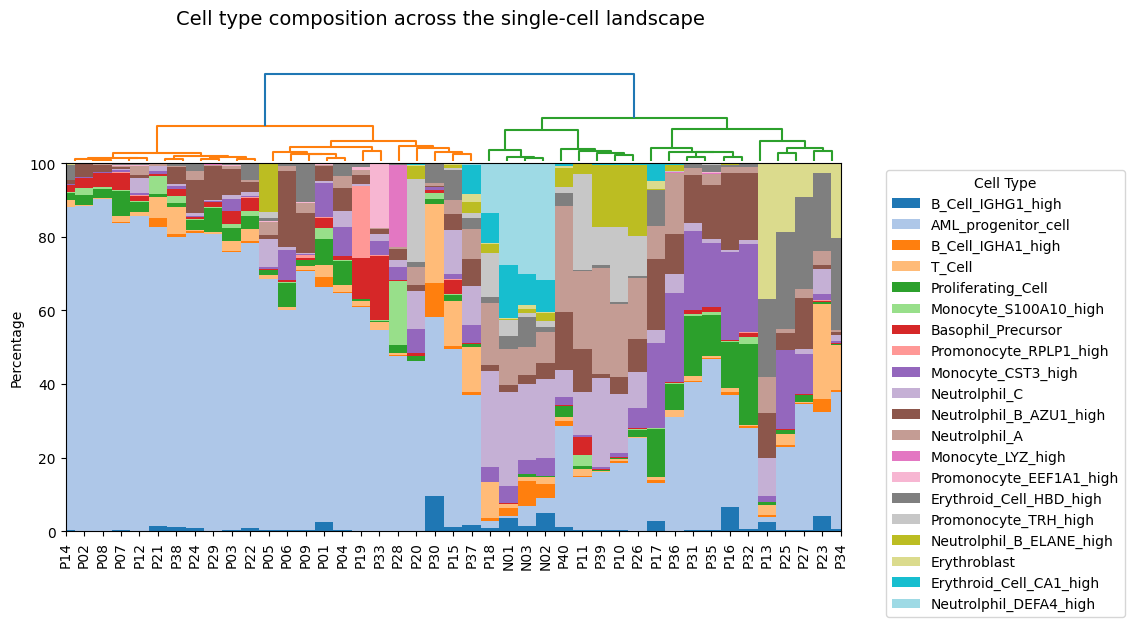

In [5]:
meta[3]  = meta[0].str.split('_', expand=True)[0]
meta[0] = meta[0].str.split('_', expand=True)[1]
pat_type = meta[3].unique()

list_cdf = []

for i in pat_type:
    pat_m = meta[meta[3] == i]
    cell_count = Counter(pat_m[2])
    c_df = DataFrame(cell_count.values(), index=cell_count.keys(), columns=[i])
    list_cdf.append(c_df)

fdf = pd.concat(list_cdf, axis=1).fillna(0)
per_df = (fdf/fdf.sum())*100
df_T = per_df.T

Z = linkage(df_T, method='ward')
leaf_order = leaves_list(Z)
ordered_samples = df_T.index[leaf_order]
df_ordered = df_T.loc[ordered_samples].T

fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 4], hspace=0.01)

ax0 = plt.subplot(gs[0])
dendro = dendrogram(Z, labels=df_T.index, leaf_rotation=90, ax=ax0, color_threshold=None)
ax0.set_xticks([])
ax0.set_yticks([])
ax0.spines[['top', 'right', 'left', 'bottom']].set_visible(False)

ax1 = plt.subplot(gs[1])
df_ordered.T.plot(kind='bar', stacked=True, ax=ax1, width=1.0, colormap='tab20')

num_of_cells = fdf.T.sort_values('AML_progenitor_cell')
num_of_cells['Total'] = fdf.T.sum(axis=1).sort_values()

ax1.set_ylabel("Percentage")
fig.suptitle('Cell type composition across the single-cell landscape', fontsize=14)
ax1.set_ylim(0, 100)
ax1.set_xlim(0, 1)
ax1.set_xticks(np.arange(len(ordered_samples)))
ax1.set_xticklabels(ordered_samples, rotation=90)
ax1.legend(title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')
fig.savefig(f"{FIGURE_DIR}/Fig_landscape.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [7]:
progen_high = list(df_ordered.columns[:23])
progen_low = list(df_ordered.columns[27:])
progen_low.append(df_ordered.columns[23])
normal_pat = ['N01', 'N02', 'N03']
progen_frac = per_df.loc['AML_progenitor_cell']
progen_frac[progen_high]

P14    87.753569
P02    88.527434
P08    90.235153
P07    83.532609
P12    85.667600
P21    81.115263
P38    78.884026
P24    80.327069
P29    80.641330
P03    75.737602
P22    77.456493
P05    68.181818
P06    59.760802
P09    70.199476
P01    64.076433
P04    64.499350
P19    60.998984
P33    54.675573
P28    47.384988
P20    46.057900
P30    48.573093
P15    48.511905
P37    35.543809
Name: AML_progenitor_cell, dtype: float64

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_85899/3537748264.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Group', y='Fraction', data=data, palette='Set2')


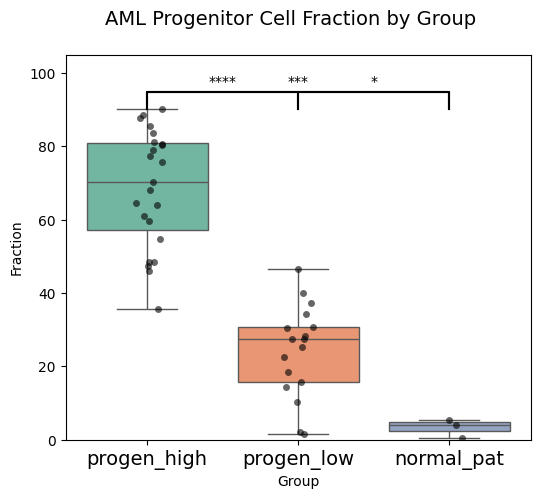

1.7350639081099548e-07 0.0007692307692307692 0.01929824561403509


In [9]:
data = pd.DataFrame({
    'Fraction': list(progen_frac[progen_high]   ) + 
                list(progen_frac[progen_low]    ) + 
                list(progen_frac[normal_pat]    ),
    'Group':    ['progen_high'] * len(progen_high) +
                ['progen_low']  * len(progen_low)  +
                ['normal_pat']  * len(normal_pat)
})

plt.figure(figsize=(6, 5))
ax = sns.boxplot(x='Group', y='Fraction', data=data, palette='Set2')
sns.stripplot(x='Group', y='Fraction', data=data, color='black', jitter=True, alpha=0.6)

high_vals = data[data['Group'] == 'progen_high']['Fraction']
low_vals  = data[data['Group'] == 'progen_low']['Fraction']
norm_vals = data[data['Group'] == 'normal_pat']['Fraction']

_, pval1 = mannwhitneyu(high_vals, low_vals, alternative='two-sided')
_, pval2 = mannwhitneyu(high_vals, norm_vals, alternative='two-sided')
_, pval3 = mannwhitneyu(low_vals, norm_vals, alternative='two-sided')

def annotate(ax, x1, x2, y, pval):
    offset = (data['Fraction'].max() - data['Fraction'].min()) * 0.05
    ax.plot([x1, x1, x2, x2], [y, y+offset, y+offset, y], lw=1.5, c='k')
    if pval < 0.0001:
        text = '****'
    elif pval < 0.001:
        text = '***'
    elif pval < 0.01:
        text = '**'
    elif pval < 0.05:
        text = '*'
    else:
        text = 'ns'
    ax.text((x1 + x2) * 0.5, y + offset * 1.2, text, ha='center', va='bottom', color='k')

y_max = data['Fraction'].max()
annotate(ax, 0, 1, y_max + 0.01, pval1)   # progen_high vs progen_low
annotate(ax, 0, 2, y_max + 0.04, pval2)   # progen_high vs normal
annotate(ax, 1, 2, y_max + 0.07, pval3)   # progen_low vs normal
ax.set_ylim(0, 105)
ax.tick_params(axis='x', labelsize=14)

plt.suptitle("AML Progenitor Cell Fraction by Group", fontsize=14, y=0.97)
plt.savefig(f"{FIGURE_DIR}/Fig_frac_boxplot.pdf", format="pdf", bbox_inches="tight")
plt.show()

print(pval1, pval2, pval3)

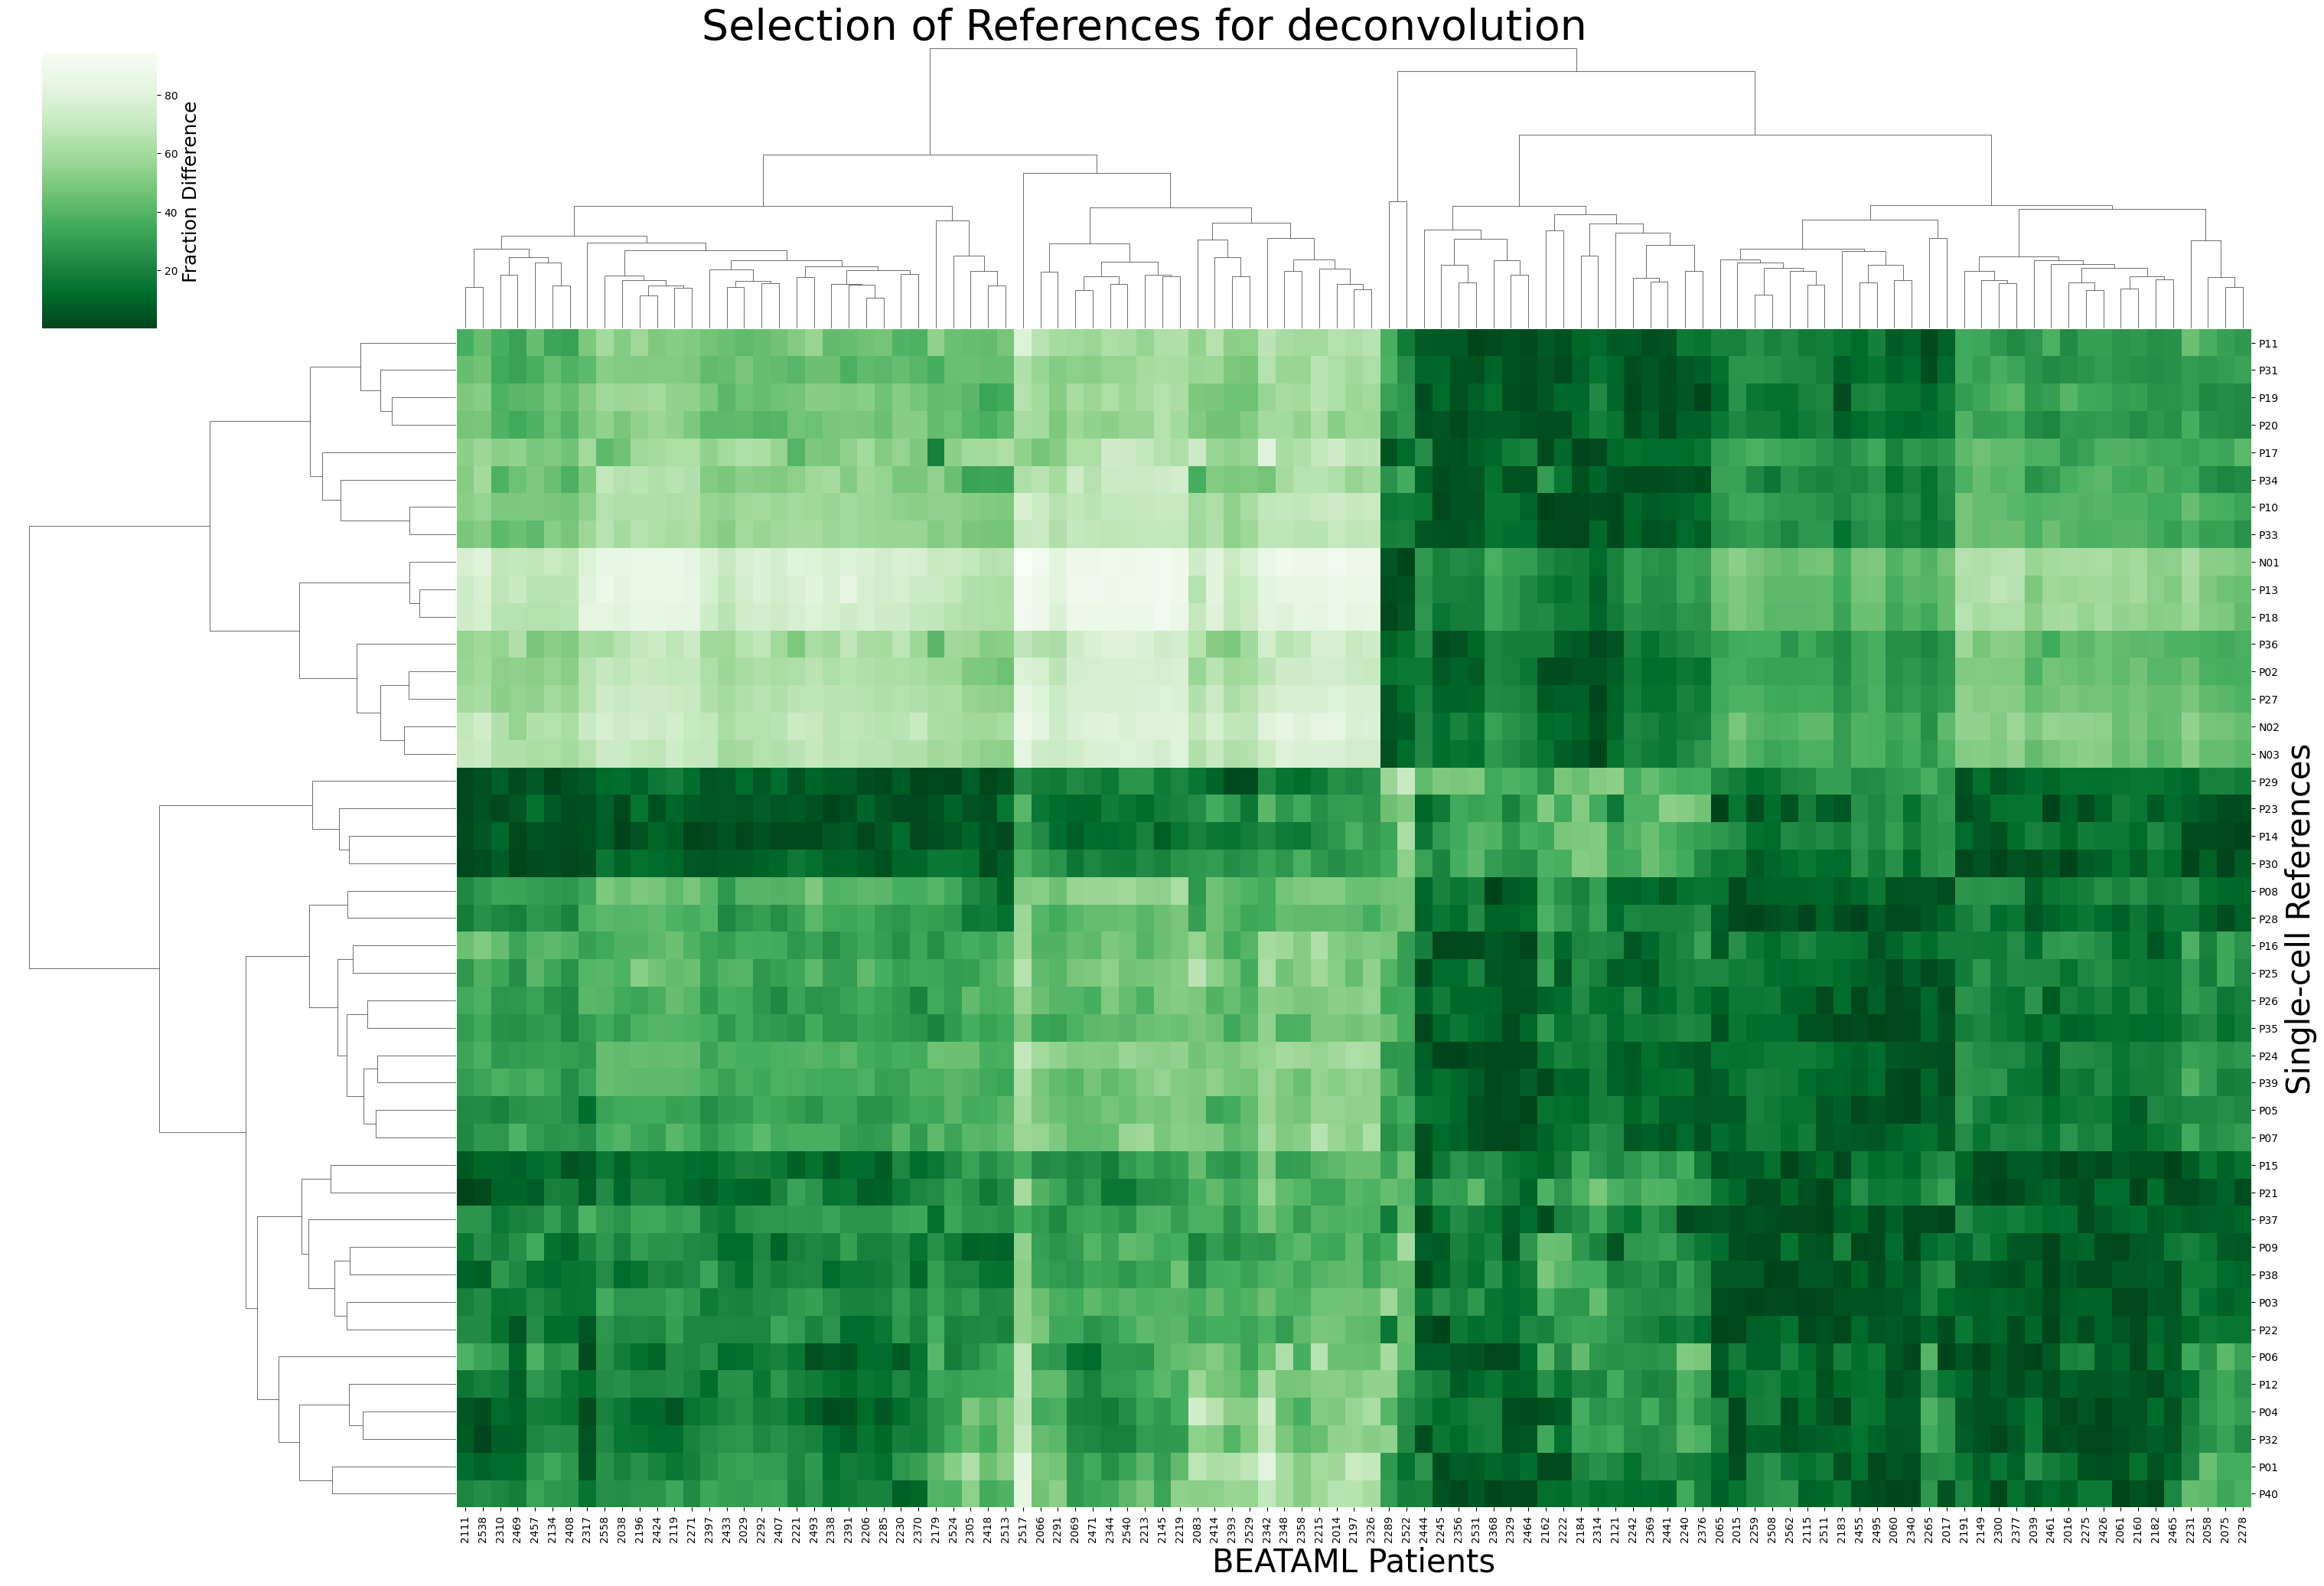

In [55]:
pat_info = pd.read_csv(CLUSTER_INFO, index_col=0)
frac_df = pd.read_csv(FRAC_DF, index_col=0)

type_X = 'X..Blasts.in.BM'

progen_df1 = frac_df*100
progen_df1.index = [int(i.split('_')[0]) for i in progen_df1.index]
progen_df2 = DataFrame(pat_info[type_X]).dropna()

ind = list(set(progen_df1.index) & set(progen_df2.index))
progen_df1 = progen_df1.loc[ind]
progen_df2 = progen_df2.loc[ind]

list_pdf = []

for i in progen_df1.columns:
    pdf = DataFrame(progen_df1[i] - progen_df2[type_X], columns=[i])
    list_pdf.append(pdf)

dist_df = pd.concat(list_pdf, axis=1)

dist_df = np.abs(dist_df.T)

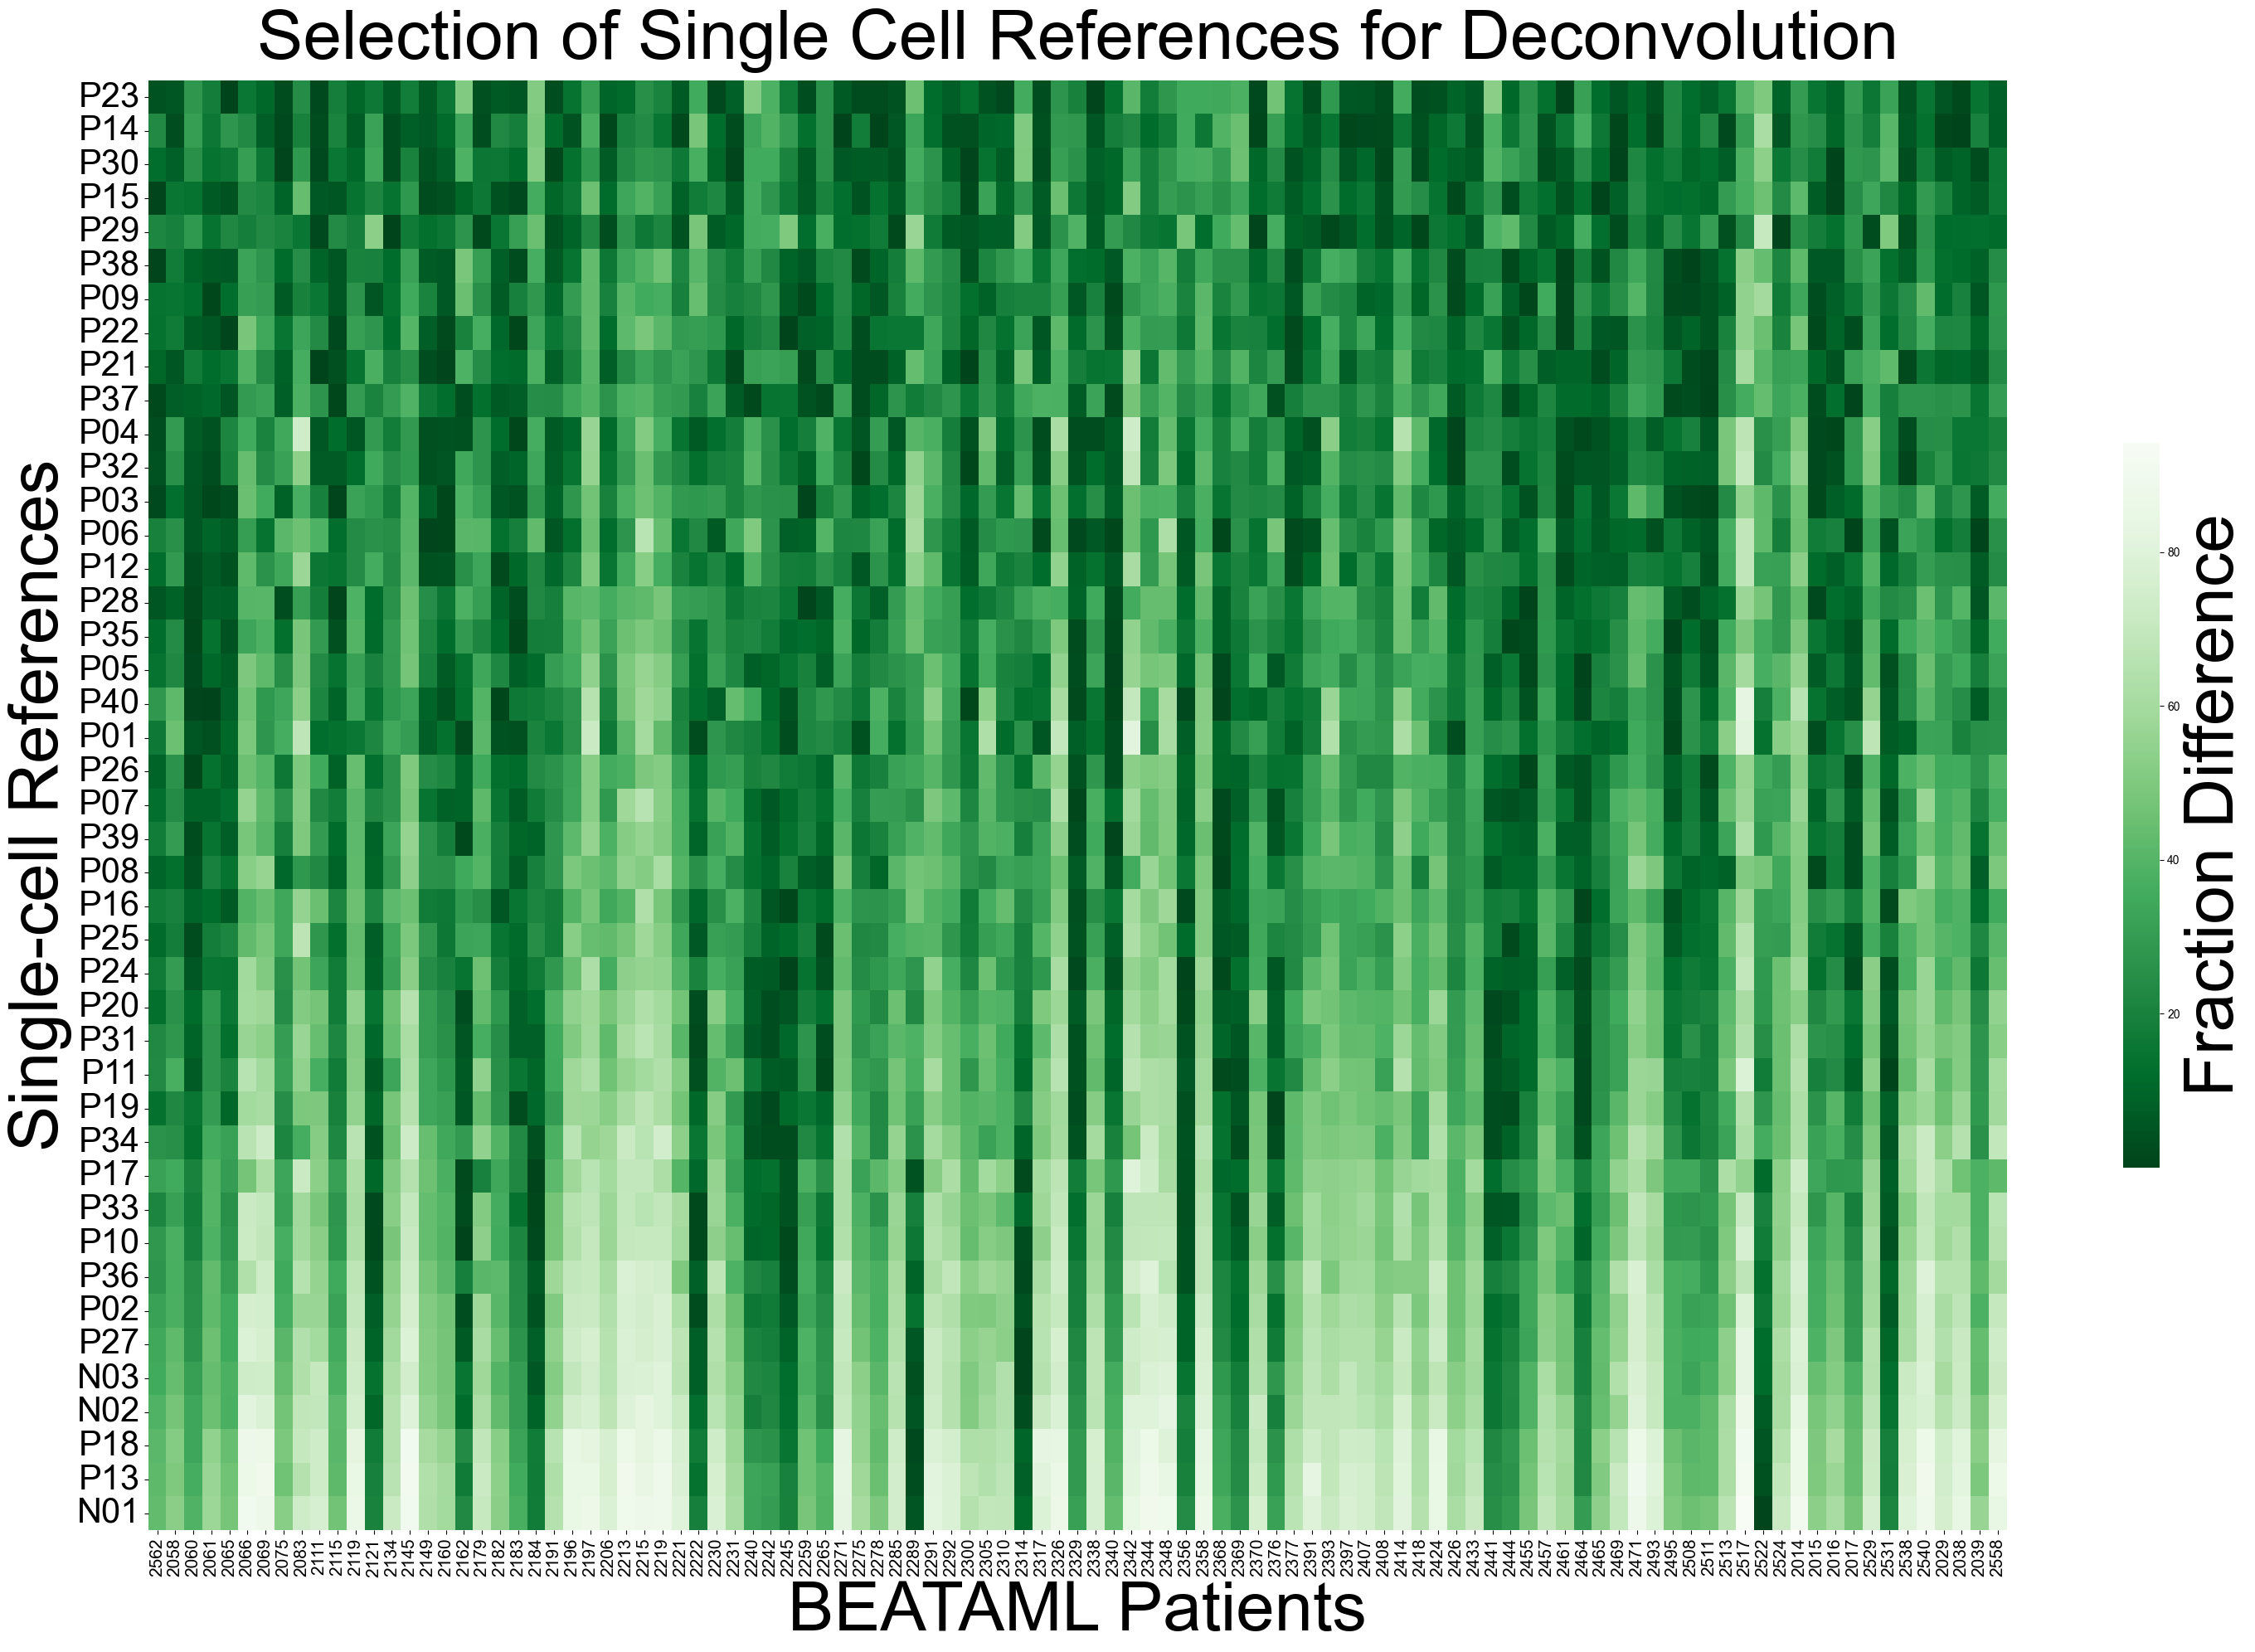

In [57]:
# Set Arial globally
plt.rcParams.update({'font.family': 'Arial'})

plt.figure(figsize=(30, 20))

dist_rnk = dist_df.mean(axis=1).sort_values(ascending=True)

ax = sns.heatmap(dist_df.reindex(dist_rnk.index), cmap='Greens_r', xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.5})

plt.title("Selection of Single Cell References for Deconvolution", fontsize=60, y=1.01)
plt.xlabel("BEATAML Patients", fontsize=60)
plt.ylabel("Single-cell References", fontsize=60)

# Colorbar label
cbar = ax.figure.axes[-1]   # last axis is the colorbar
cbar.set_ylabel("Fraction Difference", fontsize=60)

# Tick labels
ax.tick_params(axis='x', labelsize=15)
ax.tick_params(axis='y', rotation=0, labelsize=30)

plt.tight_layout()

plt.savefig(f"{FIGURE_DIR}/Fig_ref_select.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [58]:
dist_df.to_csv(DIST_DF_OUT)

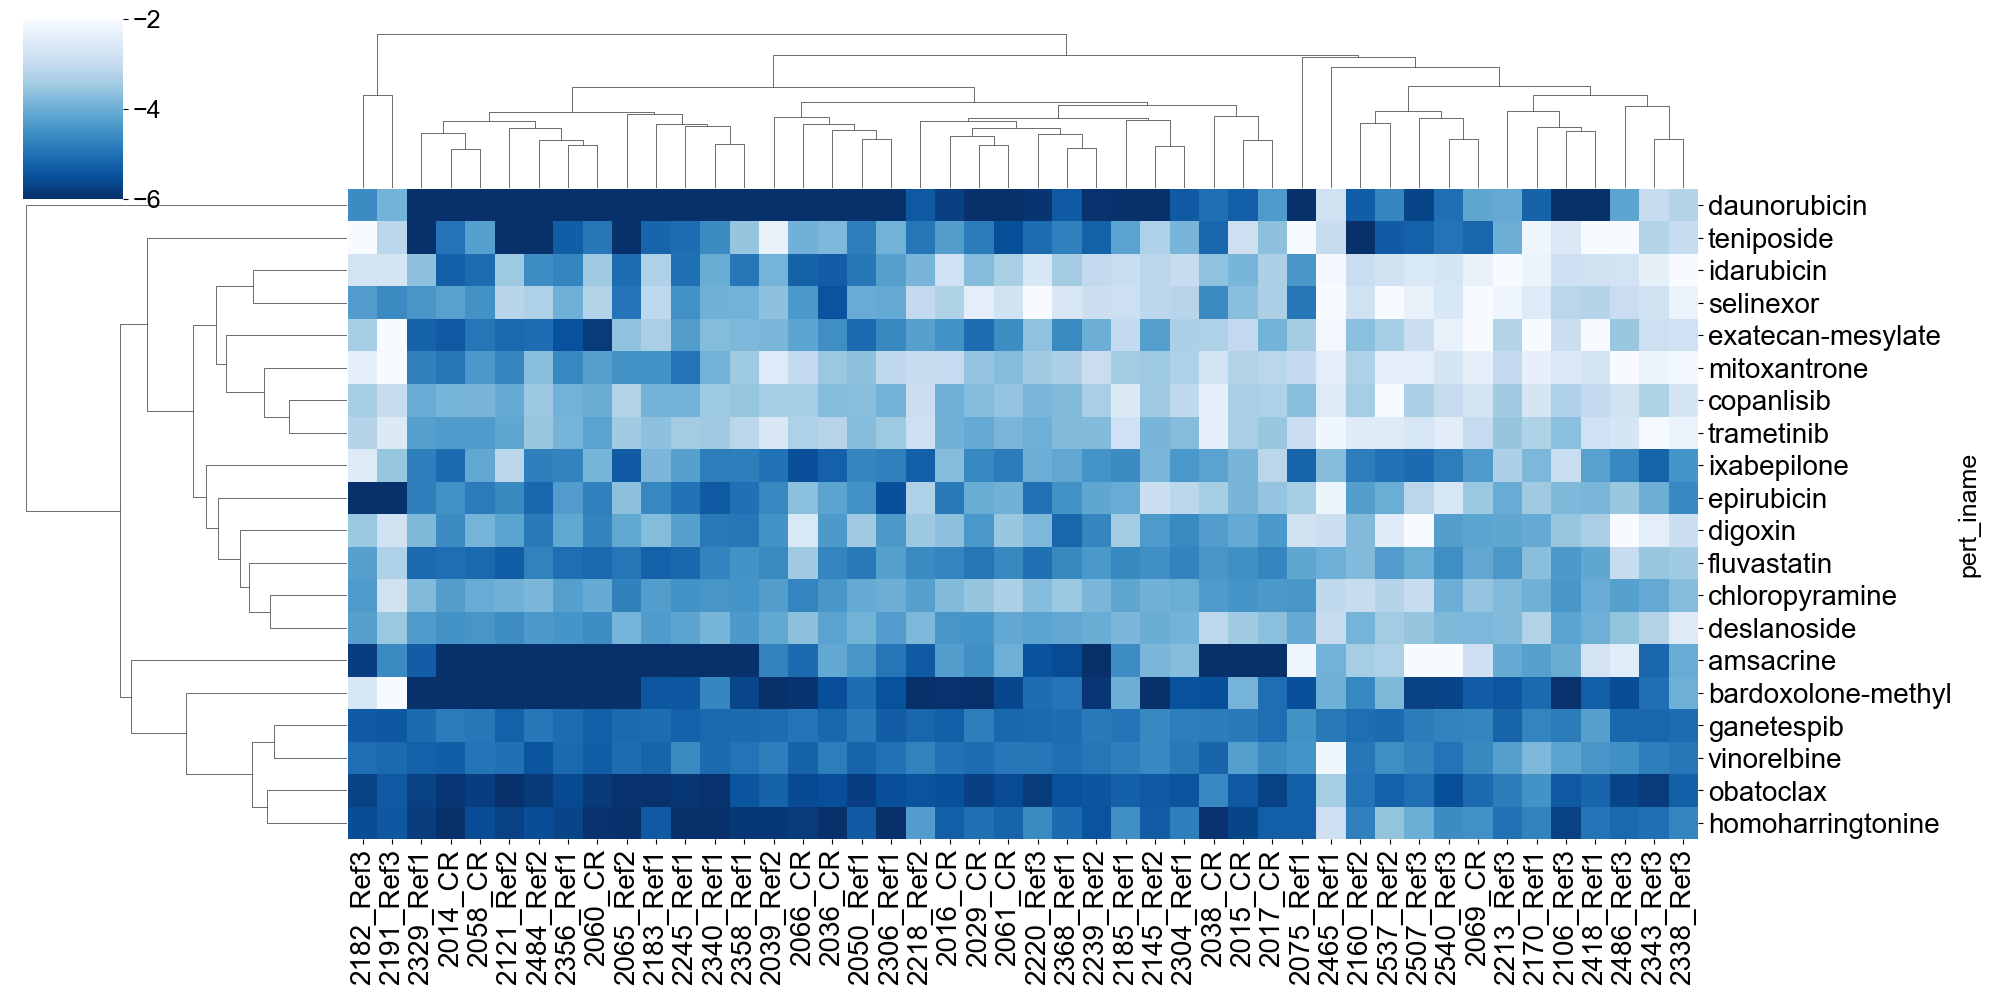

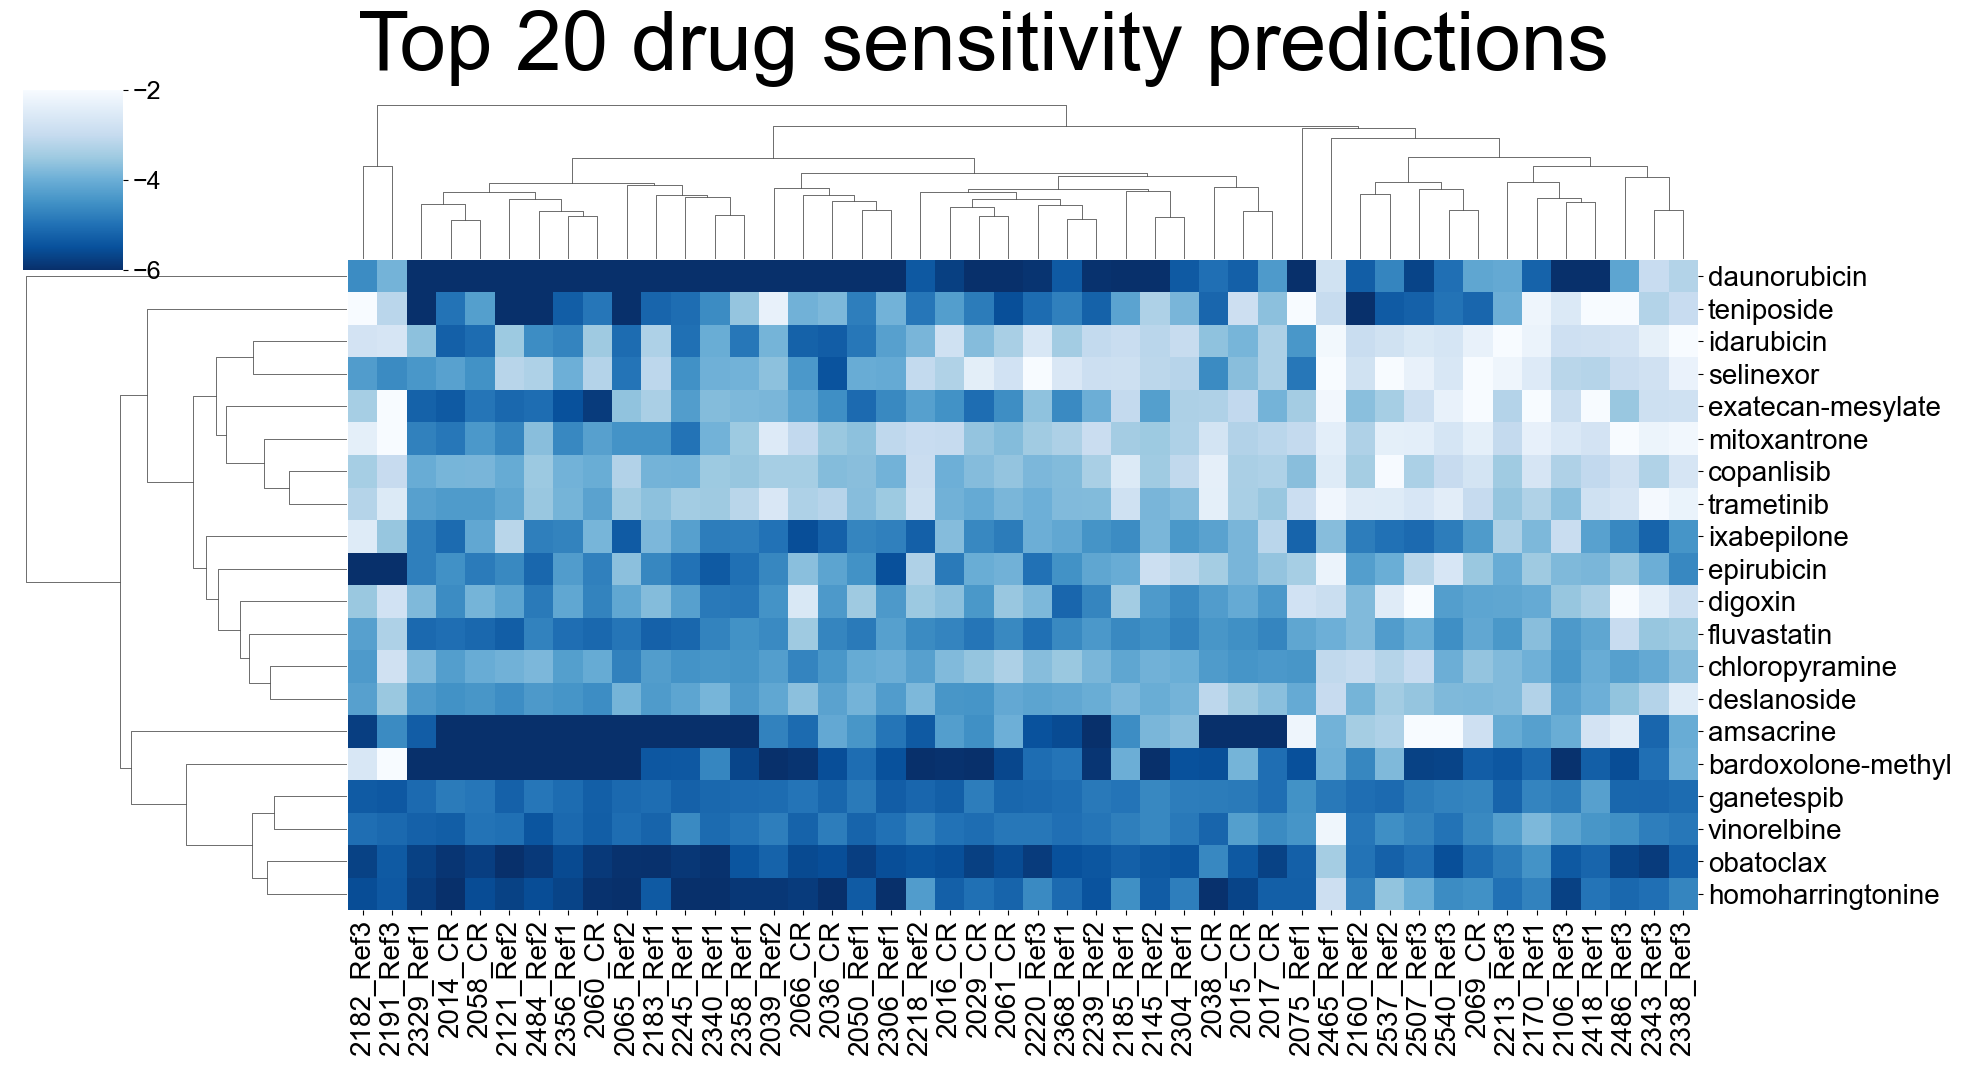

In [81]:
top_pred = predicts.loc[predicts.mean(axis=1).sort_values().head(20).index]
moa = sns.clustermap(top_pred, figsize=(20,10), xticklabels=True, yticklabels=True, cmap="Blues_r", vmax=-2, vmin=-6)
moa.ax_heatmap.set_xticklabels(moa.ax_heatmap.get_xticklabels(), fontsize=20)
moa.ax_heatmap.set_yticklabels(moa.ax_heatmap.get_yticklabels(), fontsize=20)
moa.ax_heatmap.set_ylabel('')
plt.suptitle("Top 20 drug sensitivity predictions", fontsize=60, y=1.06)
moa.fig.savefig(f"{FIGURE_DIR}/Fig_MOA.pdf", format="pdf", bbox_inches="tight")
plt.show()

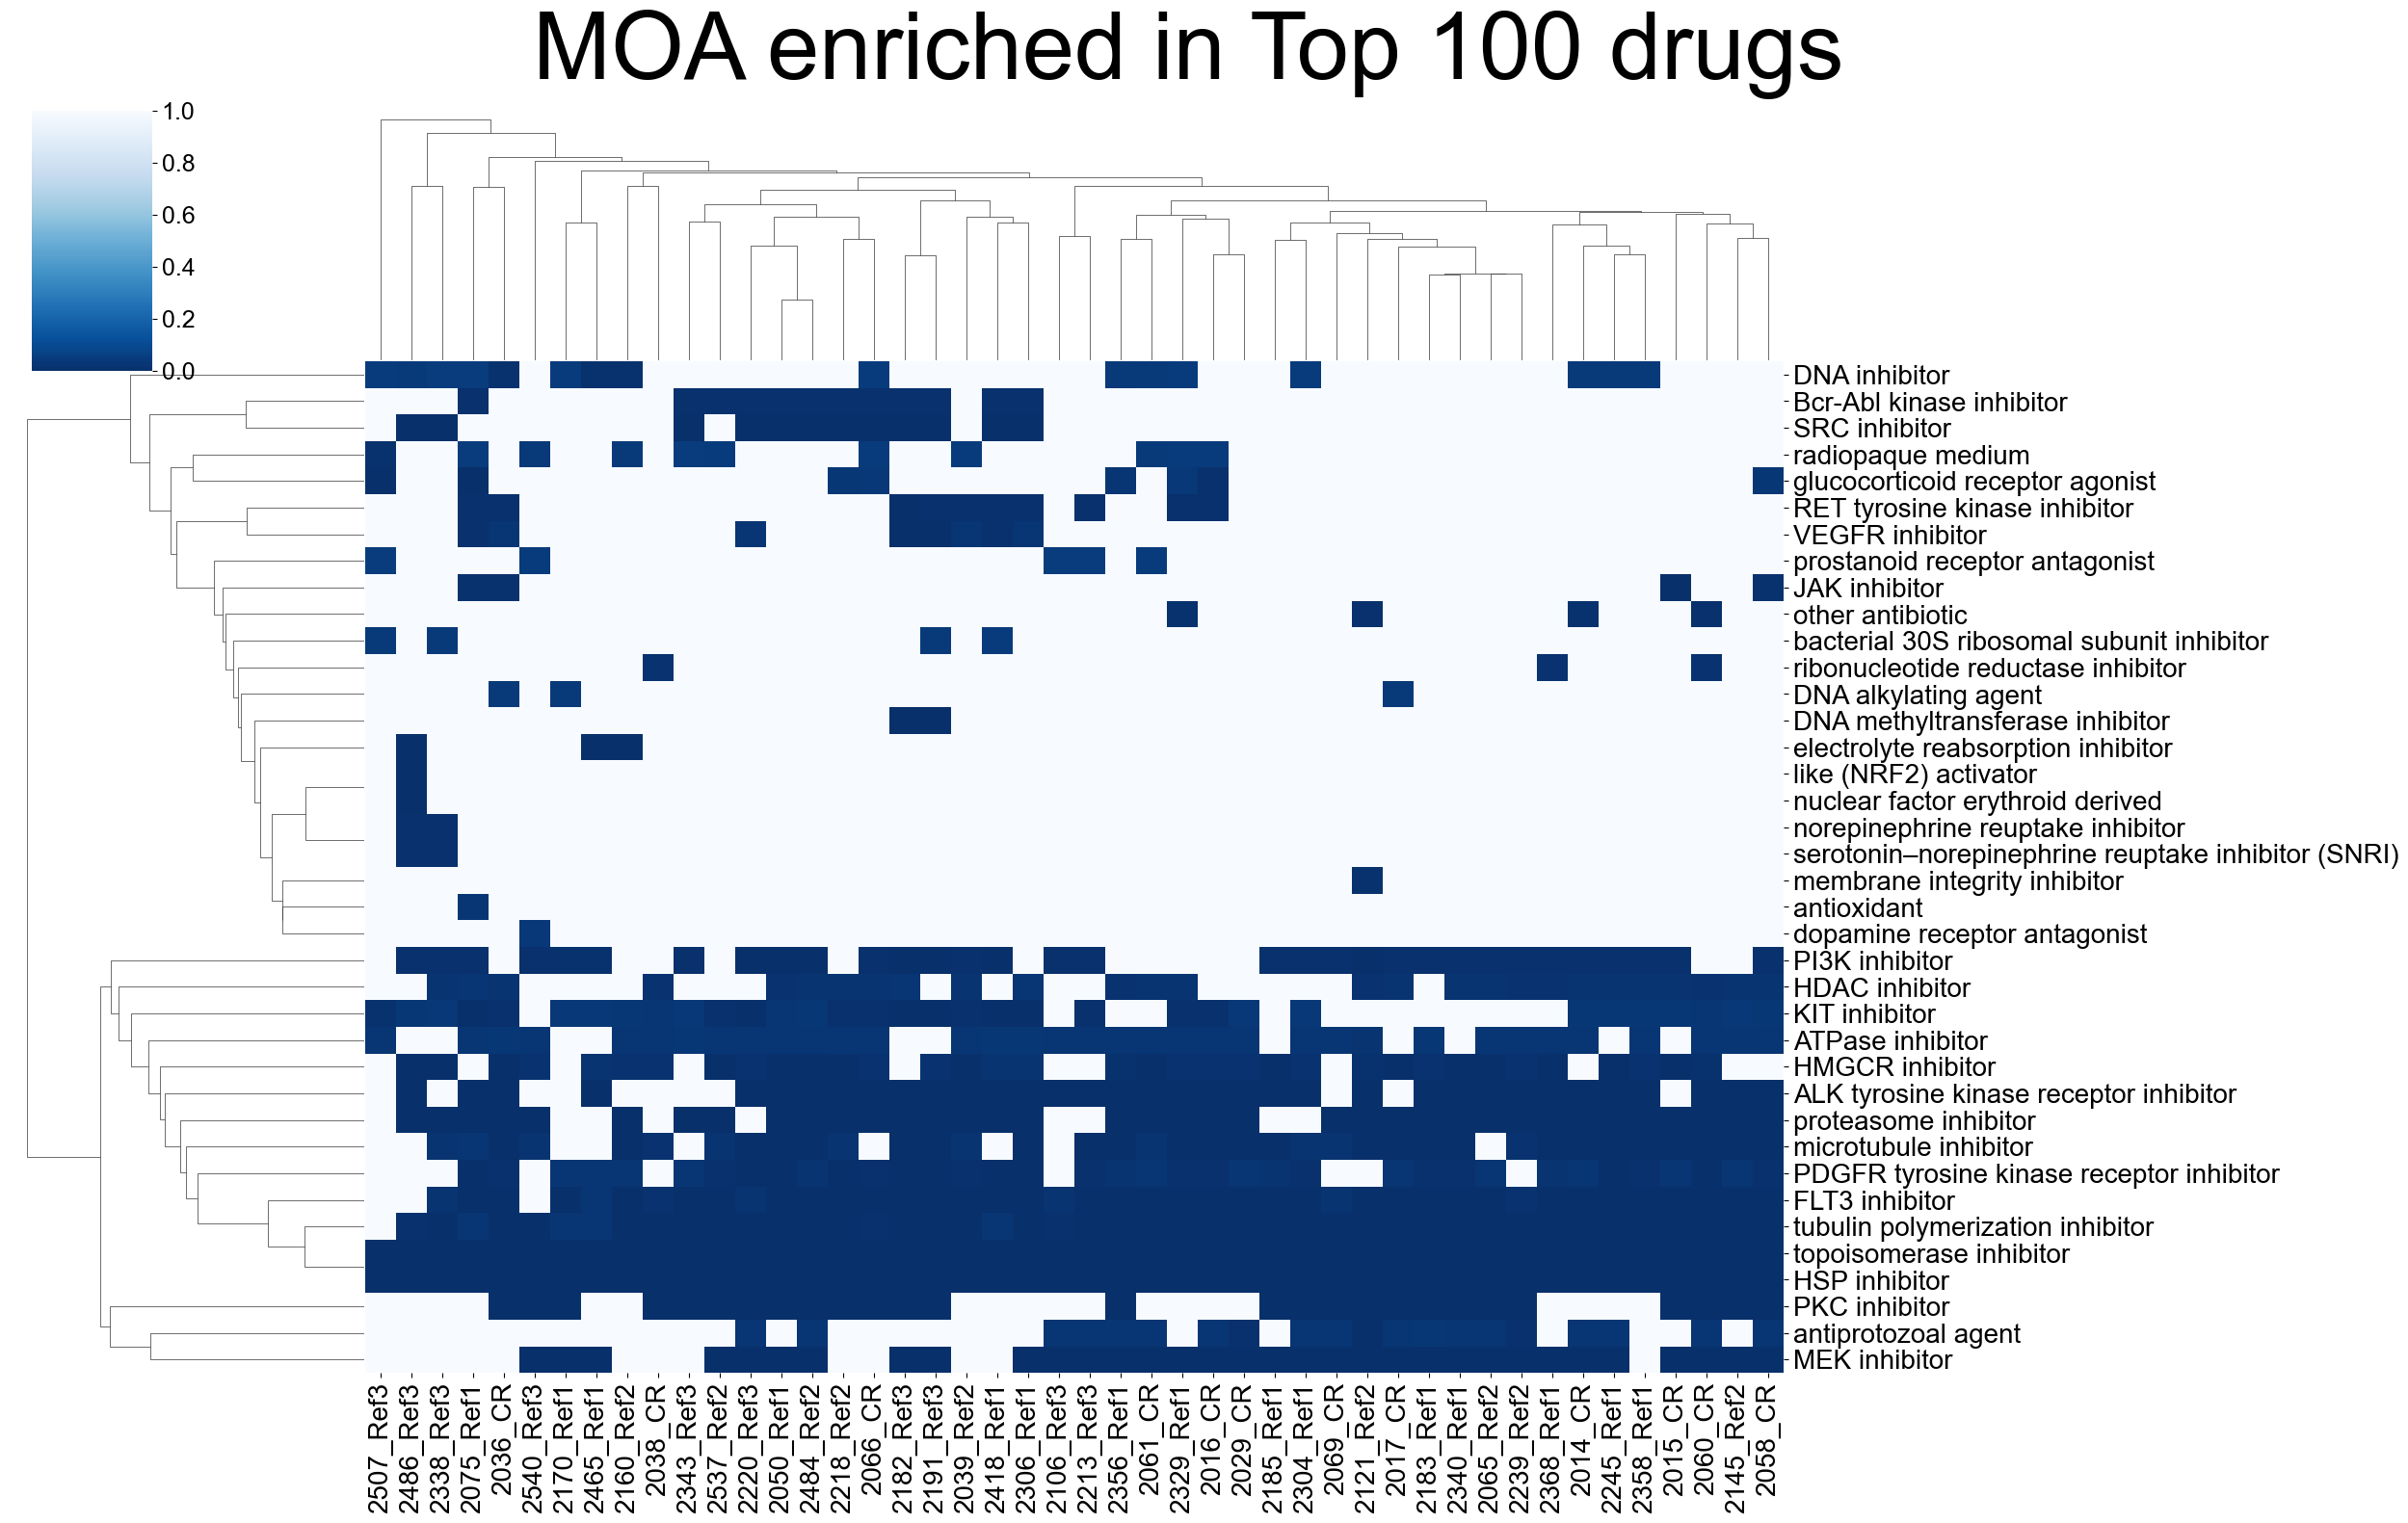

In [83]:
top_ind = list(set(predicts.mean(axis=1).sort_values().head(100).index) & set(meta_data.index))
all_ind = list(set(predicts.index) & set(meta_data.index))

top_meta = meta_data.loc[top_ind]

all_ind = list(set(predicts.index) & set(meta_data.index))
all_meta = meta_data.loc[all_ind]

list_enrich = []
list_colis = []
for col in predicts.columns:
    top_ind = list(set(predicts[col].sort_values().head(100).index) & set(meta_data.index))
    top_meta = meta_data.loc[top_ind]

    top_vals = []
    for i in top_meta.MOA.dropna().values:
        if len(i.split(',')) > 1:
            iii = i.split(', ')
            for ii in iii:
                top_vals.append(ii)
        else:
            top_vals.append(i)

    all_vals = []
    for i in all_meta.MOA.dropna().values:
        if len(i.split(',')) > 1:
            iii = i.split(', ')
            for ii in iii:
                all_vals.append(ii)
        else:
            all_vals.append(i)

    uniq = list(set(top_vals))

    list_drug = []
    list_pval = []
    list_count = []

    for u in uniq:
        len_top = len(top_vals)
        len_all = len(all_vals)

        count = Counter(top_vals)[u]

        top_feat = len([k for k in top_vals if k == u])
        all_feat = len([k for k in all_vals if k == u])

        if top_feat > 0:
            pval = hypergeom.sf(k=top_feat, M=len_all, n=all_feat, N=len_top, loc=0)
        else:
            pval = 1
        list_drug.append(u)
        list_pval.append(pval)
        list_count.append(count)

    padj = p_adjust_bh(list(list_pval)).tolist()

    perm={
        "Category":list_drug,
        "N":list_count,
        "pval":list_pval,
        "padj":padj
    }

    enrich = pd.DataFrame(perm)
    enrich = enrich[enrich['N'] > 1]
    enrich = enrich[enrich.padj < 0.05]
    list_enrich.append(enrich)
    list_colis.append(DataFrame(enrich.set_index('Category')['padj']).rename(columns={'padj':col}))

MOA_enrich = pd.concat(list_colis, axis=1).fillna(1)

cm = sns.clustermap(MOA_enrich, figsize=(25, 15), xticklabels=True, yticklabels=True, cmap="Blues_r", vmax=1, vmin=0)
cm.ax_heatmap.set_xticklabels(cm.ax_heatmap.get_xticklabels(), fontsize=20)
cm.ax_heatmap.set_yticklabels(cm.ax_heatmap.get_yticklabels(), fontsize=20)
cm.ax_heatmap.set_ylabel('')
plt.suptitle("MOA enriched in Top 100 drugs", fontsize=70, y=1.05)
plt.show()
cm.fig.savefig(f"{FIGURE_DIR}/Fig_MOA_enrich.pdf", format="pdf", bbox_inches="tight")

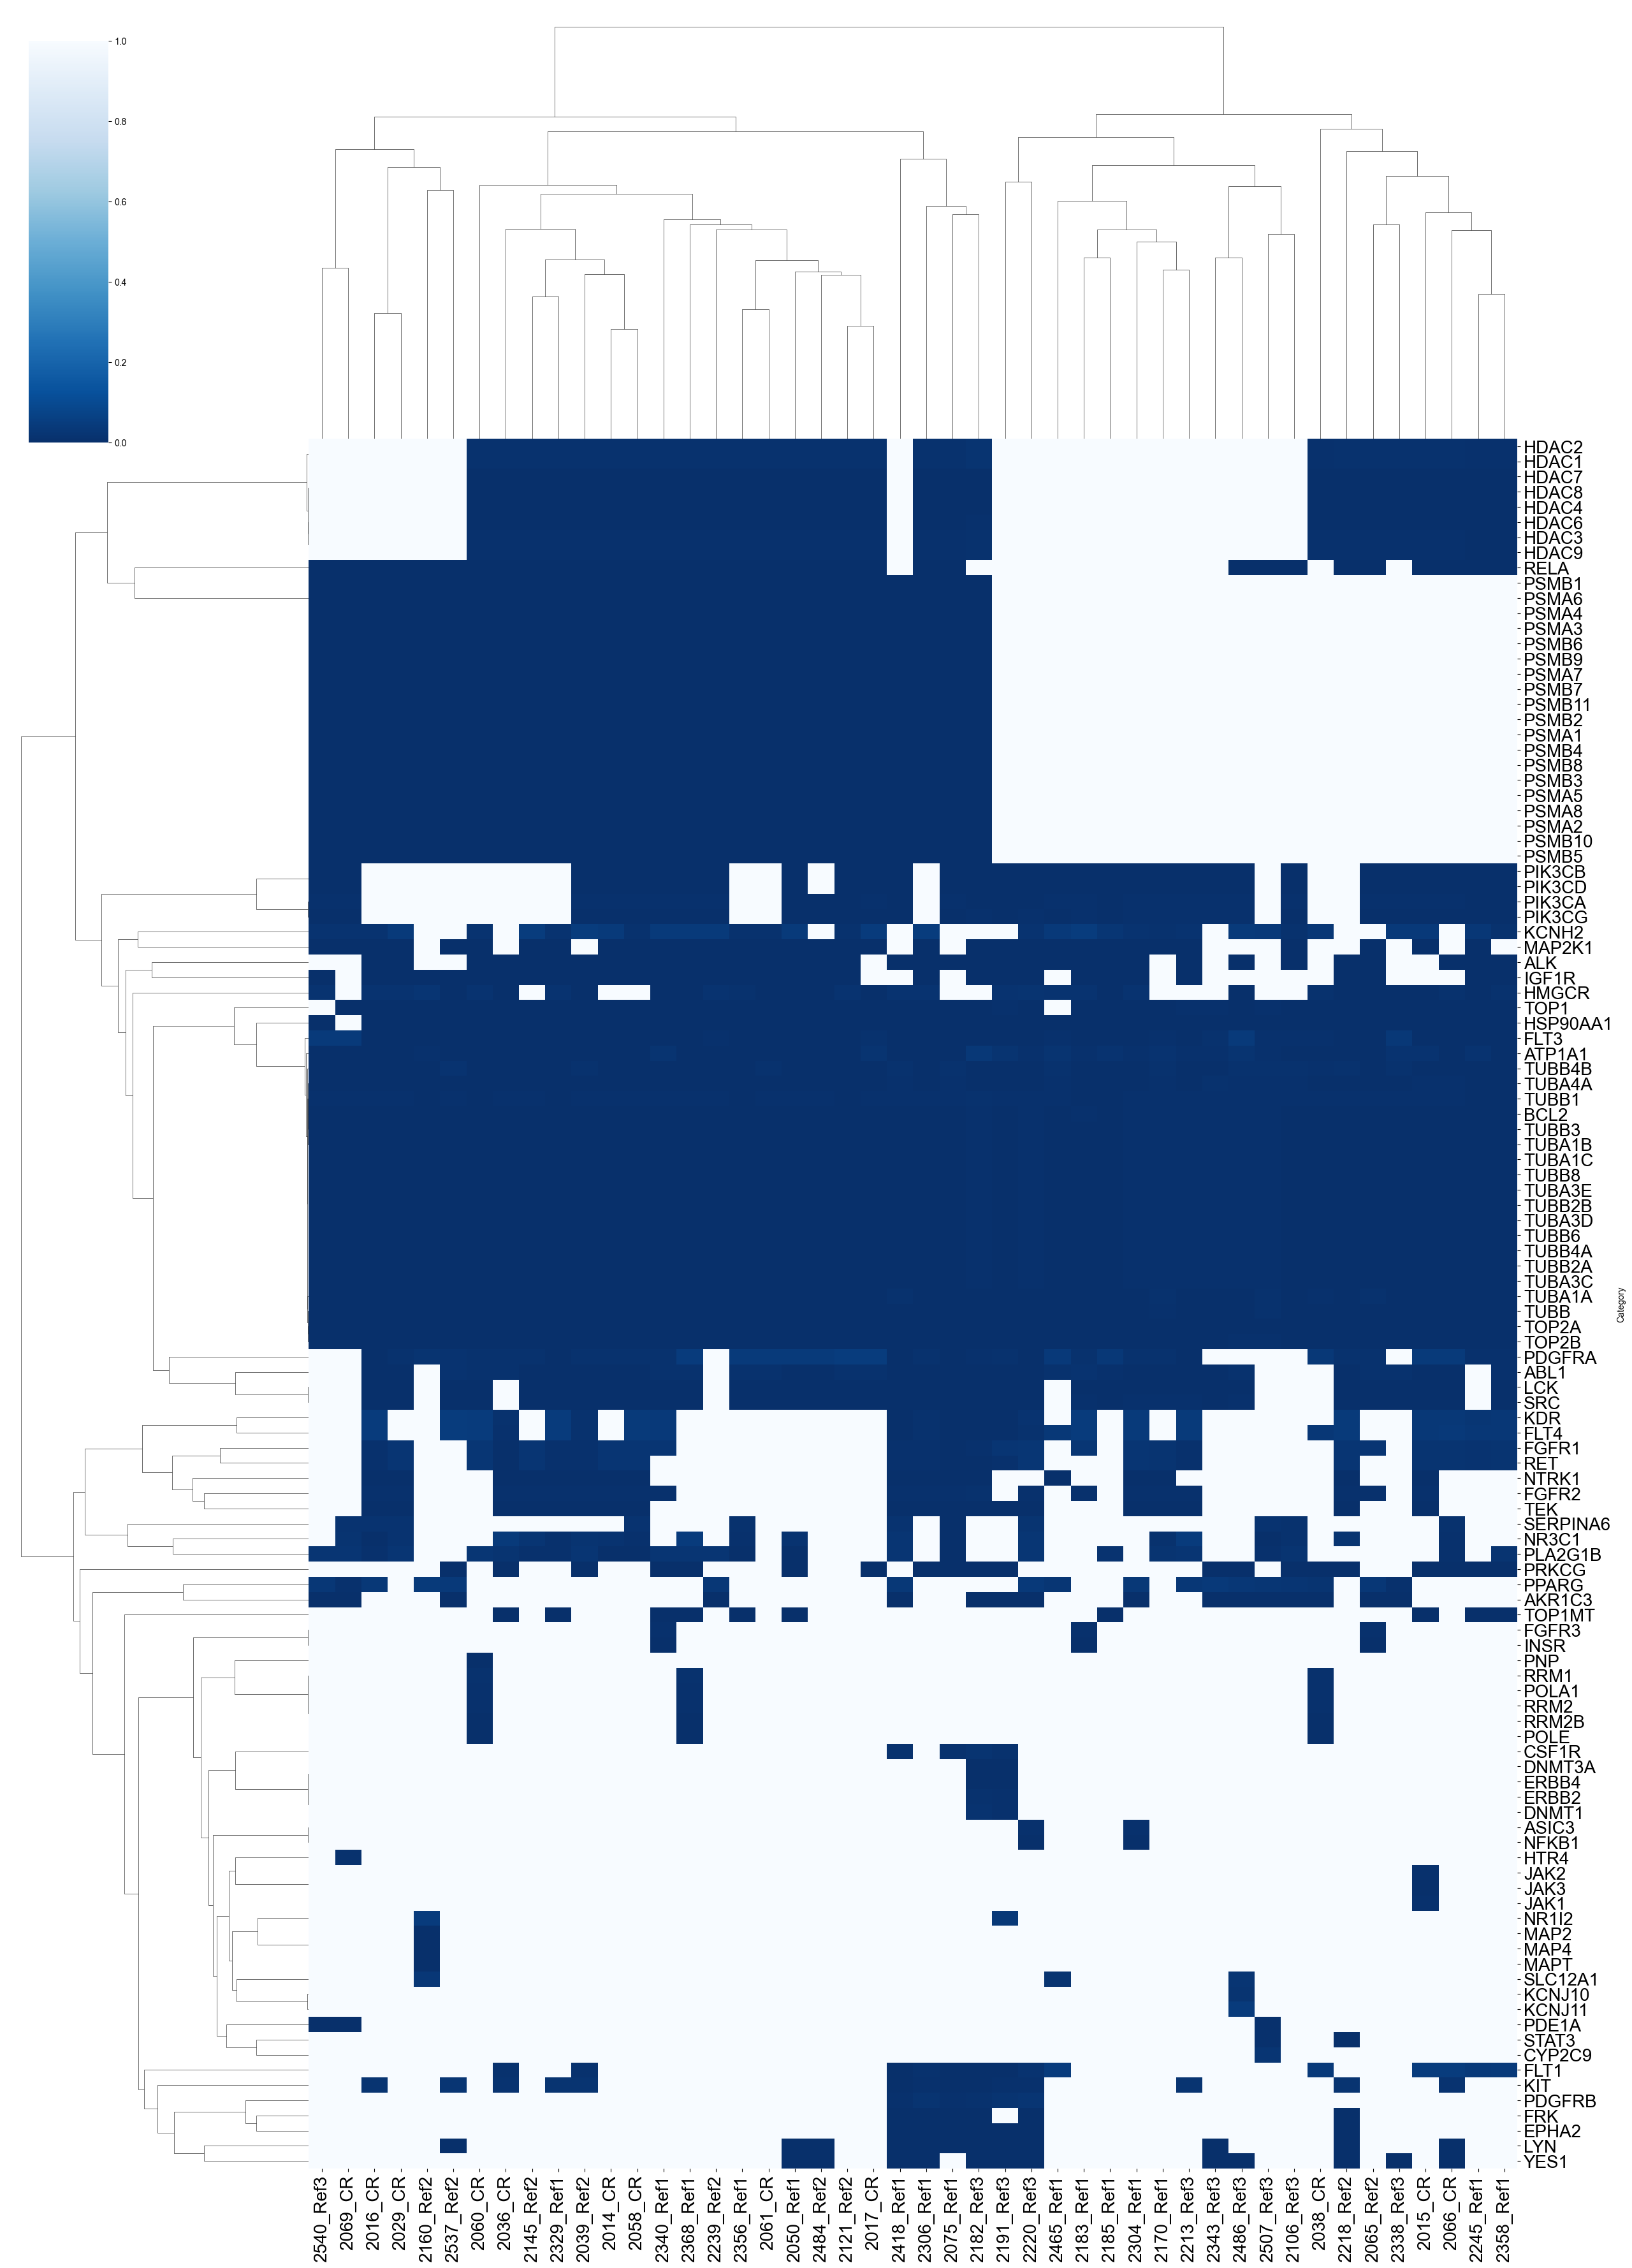

In [62]:
list_enrich = []
list_colis = []
for col in predicts.columns:
    top_ind = list(set(predicts[col].sort_values().head(100).index) & set(meta_data.index))
    top_meta = meta_data.loc[top_ind]

    top_vals = []
    for i in top_meta.Target.dropna().values:
        if len(i.split(',')) > 1:
            iii = i.split(', ')
            for ii in iii:
                top_vals.append(ii)
        else:
            top_vals.append(i)

    all_vals = []
    for i in all_meta.Target.dropna().values:
        if len(i.split(',')) > 1:
            iii = i.split(', ')
            for ii in iii:
                all_vals.append(ii)
        else:
            all_vals.append(i)

    uniq = list(set(top_vals))

    list_drug = []
    list_pval = []
    list_count = []

    for u in uniq:
        len_top = len(top_vals)
        len_all = len(all_vals)

        count = Counter(top_vals)[u]

        top_feat = len([k for k in top_vals if k == u])
        all_feat = len([k for k in all_vals if k == u])

        if top_feat > 0:
            pval = hypergeom.sf(k=top_feat, M=len_all, n=all_feat, N=len_top, loc=0)
        else:
            pval = 1
        list_drug.append(u)
        list_pval.append(pval)
        list_count.append(count)

    padj = p_adjust_bh(list(list_pval)).tolist()

    perm={
        "Category":list_drug,
        "N":list_count,
        "pval":list_pval,
        "padj":padj
    }

    enrich = pd.DataFrame(perm)
    enrich = enrich[enrich['N'] > 1]
    enrich = enrich[enrich.padj < 0.05]
    list_enrich.append(enrich)
    list_colis.append(DataFrame(enrich.set_index('Category')['padj']).rename(columns={'padj':col}))

Target_enrich = pd.concat(list_colis, axis=1).fillna(1)

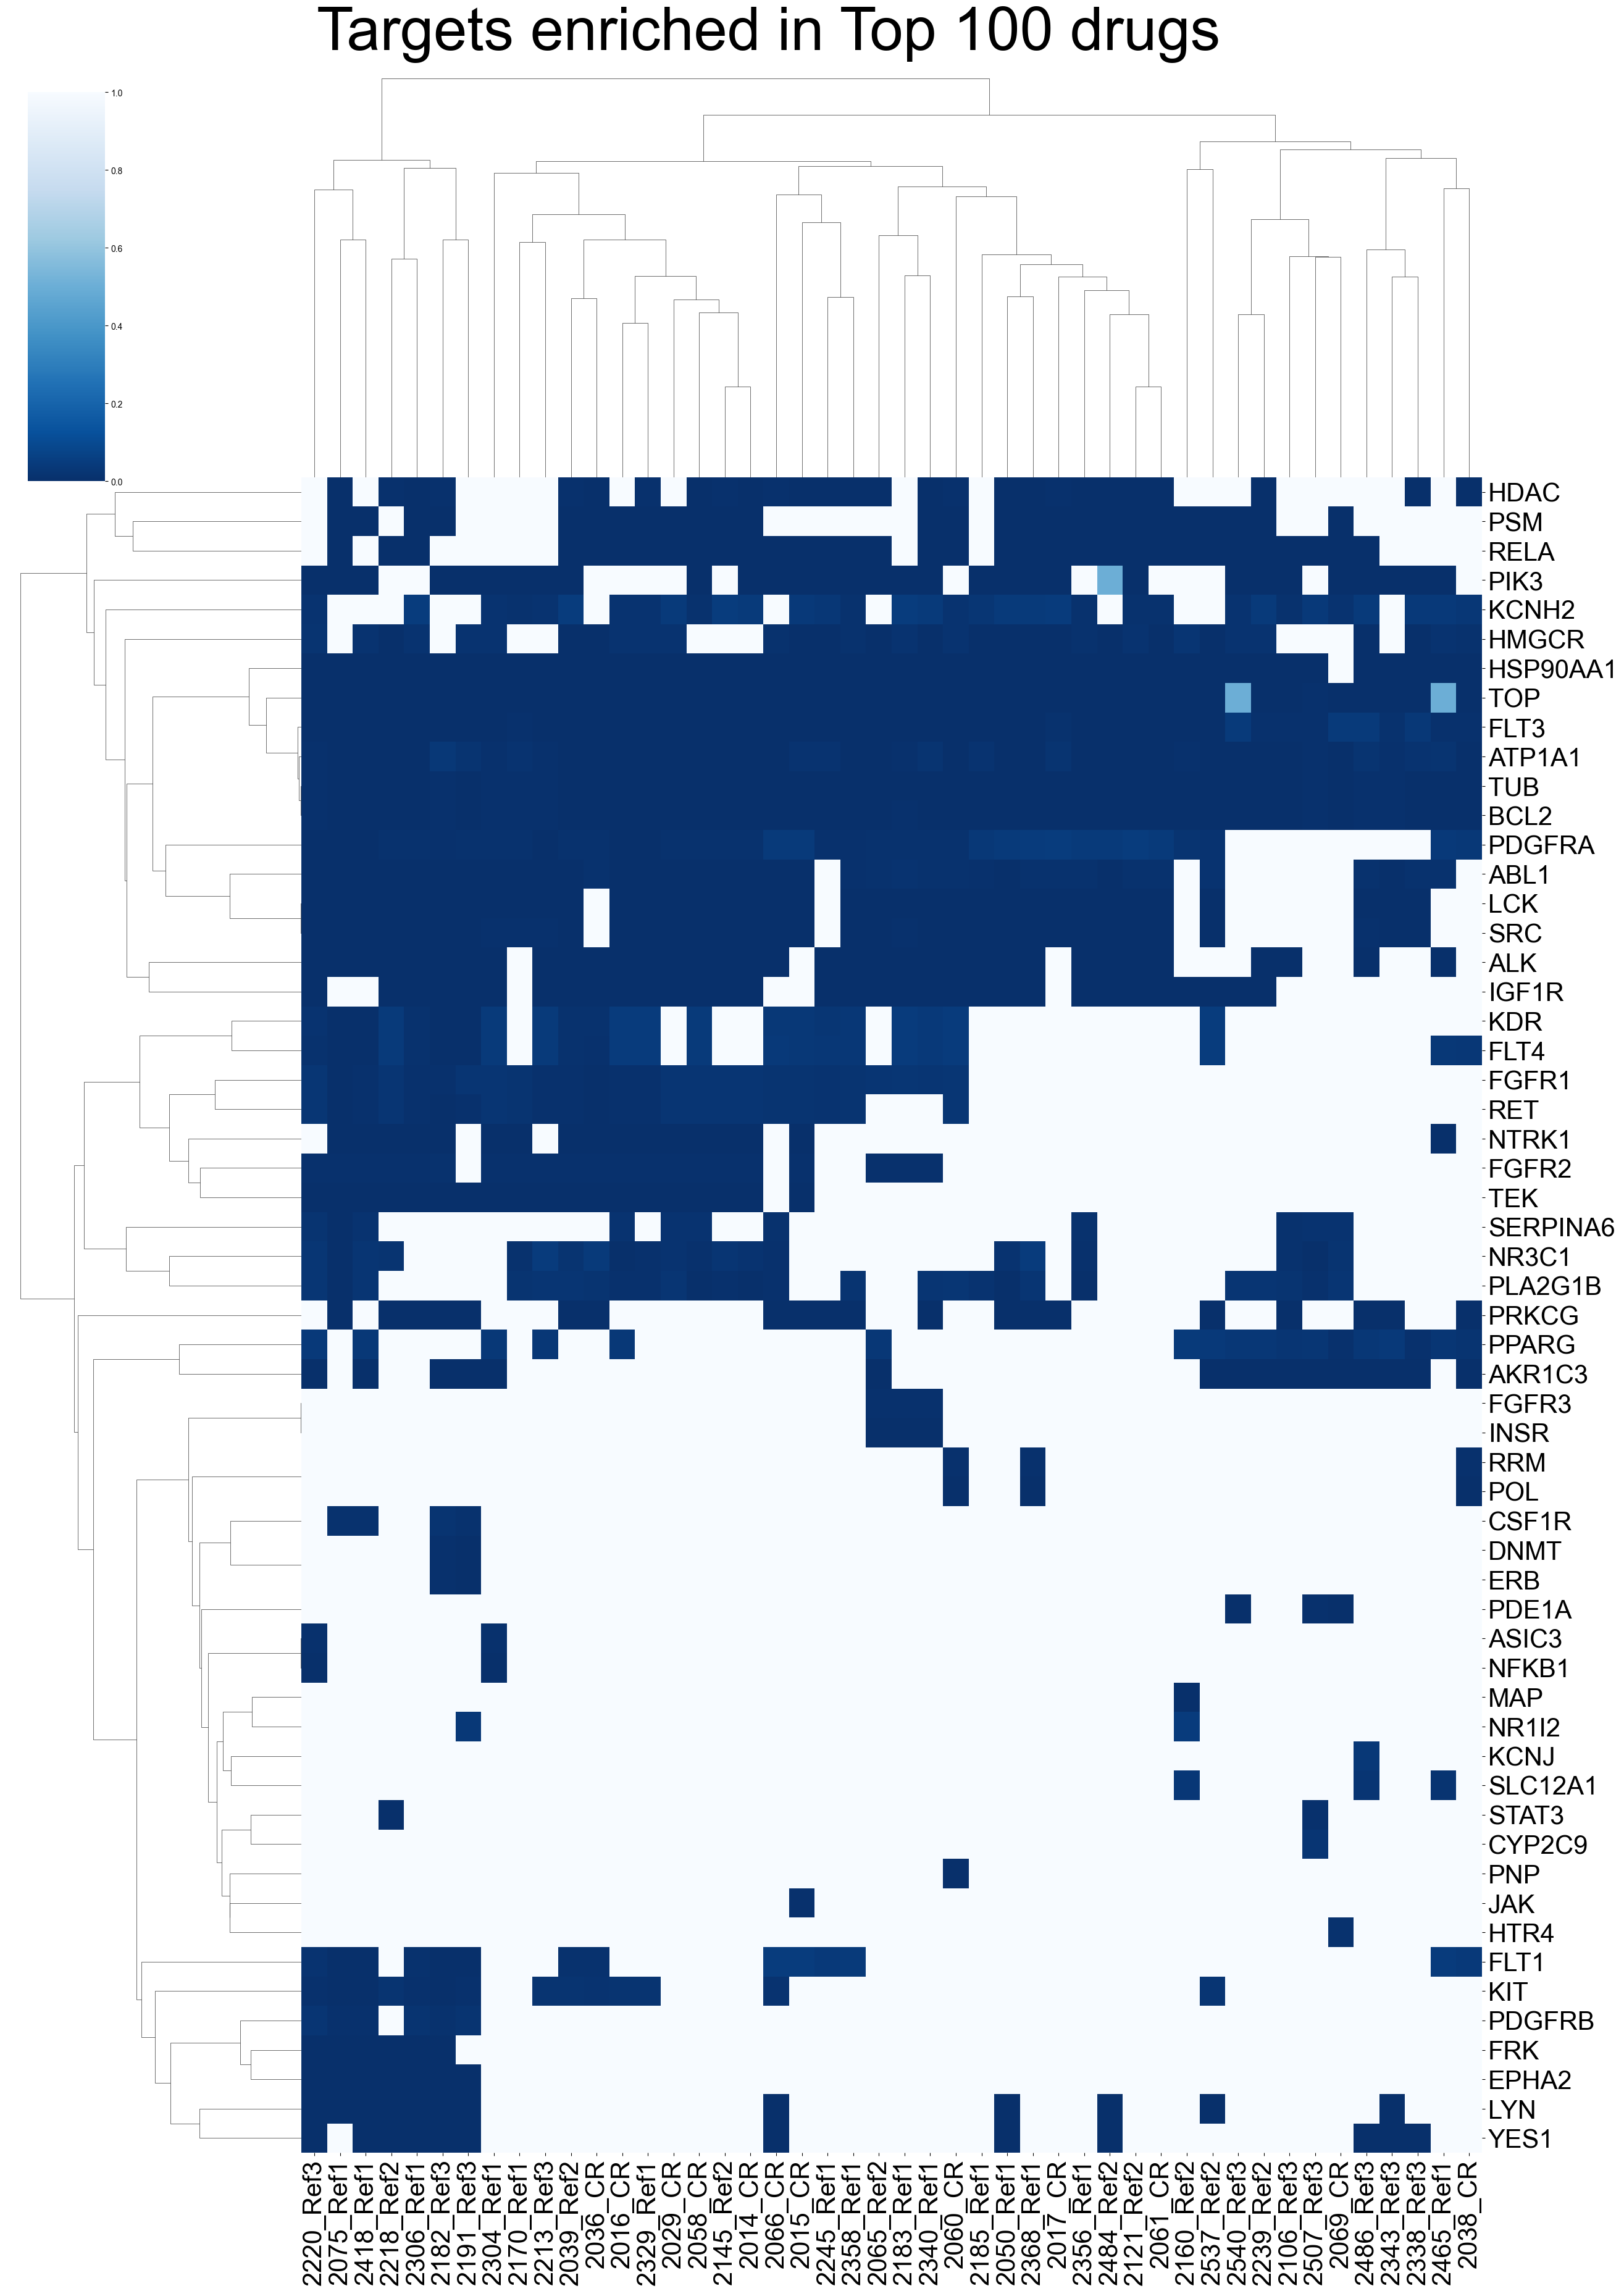

In [63]:
keywords = ['HDAC', 'PSM', 'PIK3', 'TUB', 'TOP', 'RRM', 'POL', 'DNMT', 'JAK', 'MAP', 'KCNJ', 'ERB']

medians = []
excl_list = []

for key in keywords:
    subset = Target_enrich[Target_enrich.index.str.contains(key)]
    median_row = subset.median().to_frame().T
    median_row.index = [key]  # Set index to the keyword
    medians.append(median_row)
    list_ind = Target_enrich.index[Target_enrich.index.str.contains(key)]
    for i in list_ind:
        excl_list.append(i)

median_Target_enrich = pd.concat(medians)

targetnomult = Target_enrich.loc[Target_enrich.index[~Target_enrich.index.isin(excl_list)]]

median_Target_enrich = pd.concat([median_Target_enrich, targetnomult])
cm = sns.clustermap(median_Target_enrich, figsize=(25, 35), xticklabels=True, yticklabels=True, cmap="Blues_r", vmax=1, vmin=0)
cm.ax_heatmap.set_xticklabels(cm.ax_heatmap.get_xticklabels(), fontsize=30)
cm.ax_heatmap.set_yticklabels(cm.ax_heatmap.get_yticklabels(), fontsize=30)
plt.suptitle("Targets enriched in Top 100 drugs", fontsize=70, y=1.02)
plt.show()
cm.fig.savefig(f"{FIGURE_DIR}/Fig_target_enrich.pdf", format="pdf", bbox_inches="tight")

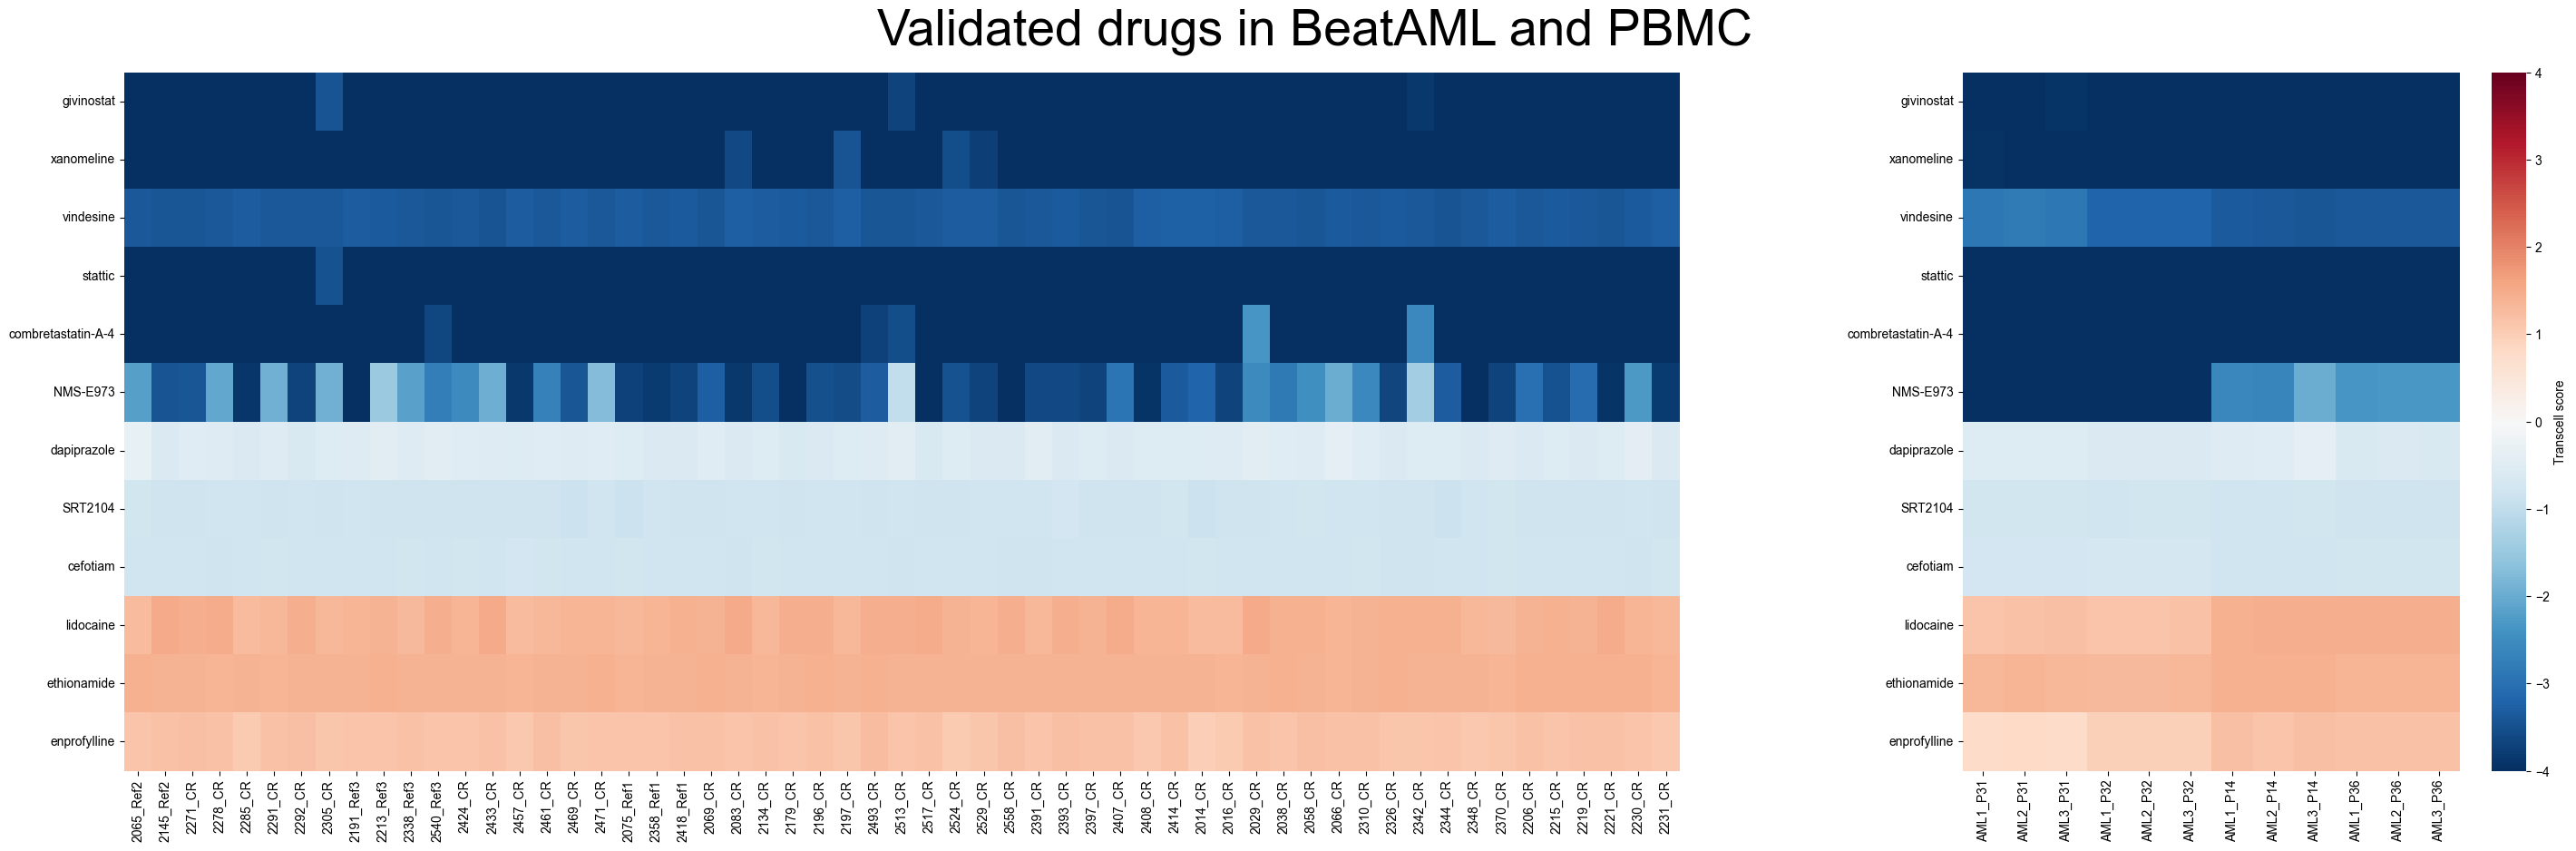

In [65]:
selected_compounds = ['givinostat', 'xanomeline', 'vindesine', 'stattic', 'combretastatin-A-4', 'NMS-E973', 'dapiprazole', 'SRT2104', 'cefotiam', 'lidocaine', 'ethionamide', 'enprofylline']

sel_df = all_df.loc[selected_compounds]
progen_pbmc = pbmc_df[pbmc_df.columns[pbmc_df.columns.str.contains('AML_progenitor_cell')]]
progen_pbmc.columns = [p.split('_AML_pro')[0] for p in progen_pbmc.columns]
sel_pbmc_df = progen_pbmc.loc[selected_compounds]

fig, (ax,ax2) = plt.subplots(1,2, figsize=(35,10), gridspec_kw={'width_ratios': [5, 2], 'height_ratios':[5]})
sns.heatmap(sel_df, ax=ax, cbar=False, cmap="RdBu_r", center=0, vmin=-4, vmax=4, xticklabels=True, yticklabels=True)
sns.heatmap(sel_pbmc_df, cbar_kws={'label': 'Transcell score'}, cmap="RdBu_r", ax=ax2, center=0, vmin=-4, vmax=4, xticklabels=True, yticklabels=True)
fig.suptitle(f'Validated drugs in BeatAML and PBMC', fontsize=40, verticalalignment='top', y=0.95)
plt.rcParams.update({'font.size': 18})
fig.subplots_adjust(wspace=0.26)
plt.savefig(f"{FIGURE_DIR}/Fig_all.pdf", format="pdf", bbox_inches="tight")
plt.show()

/Users/leshchi4/opt/miniconda3/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/leshchi4/opt/miniconda3/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


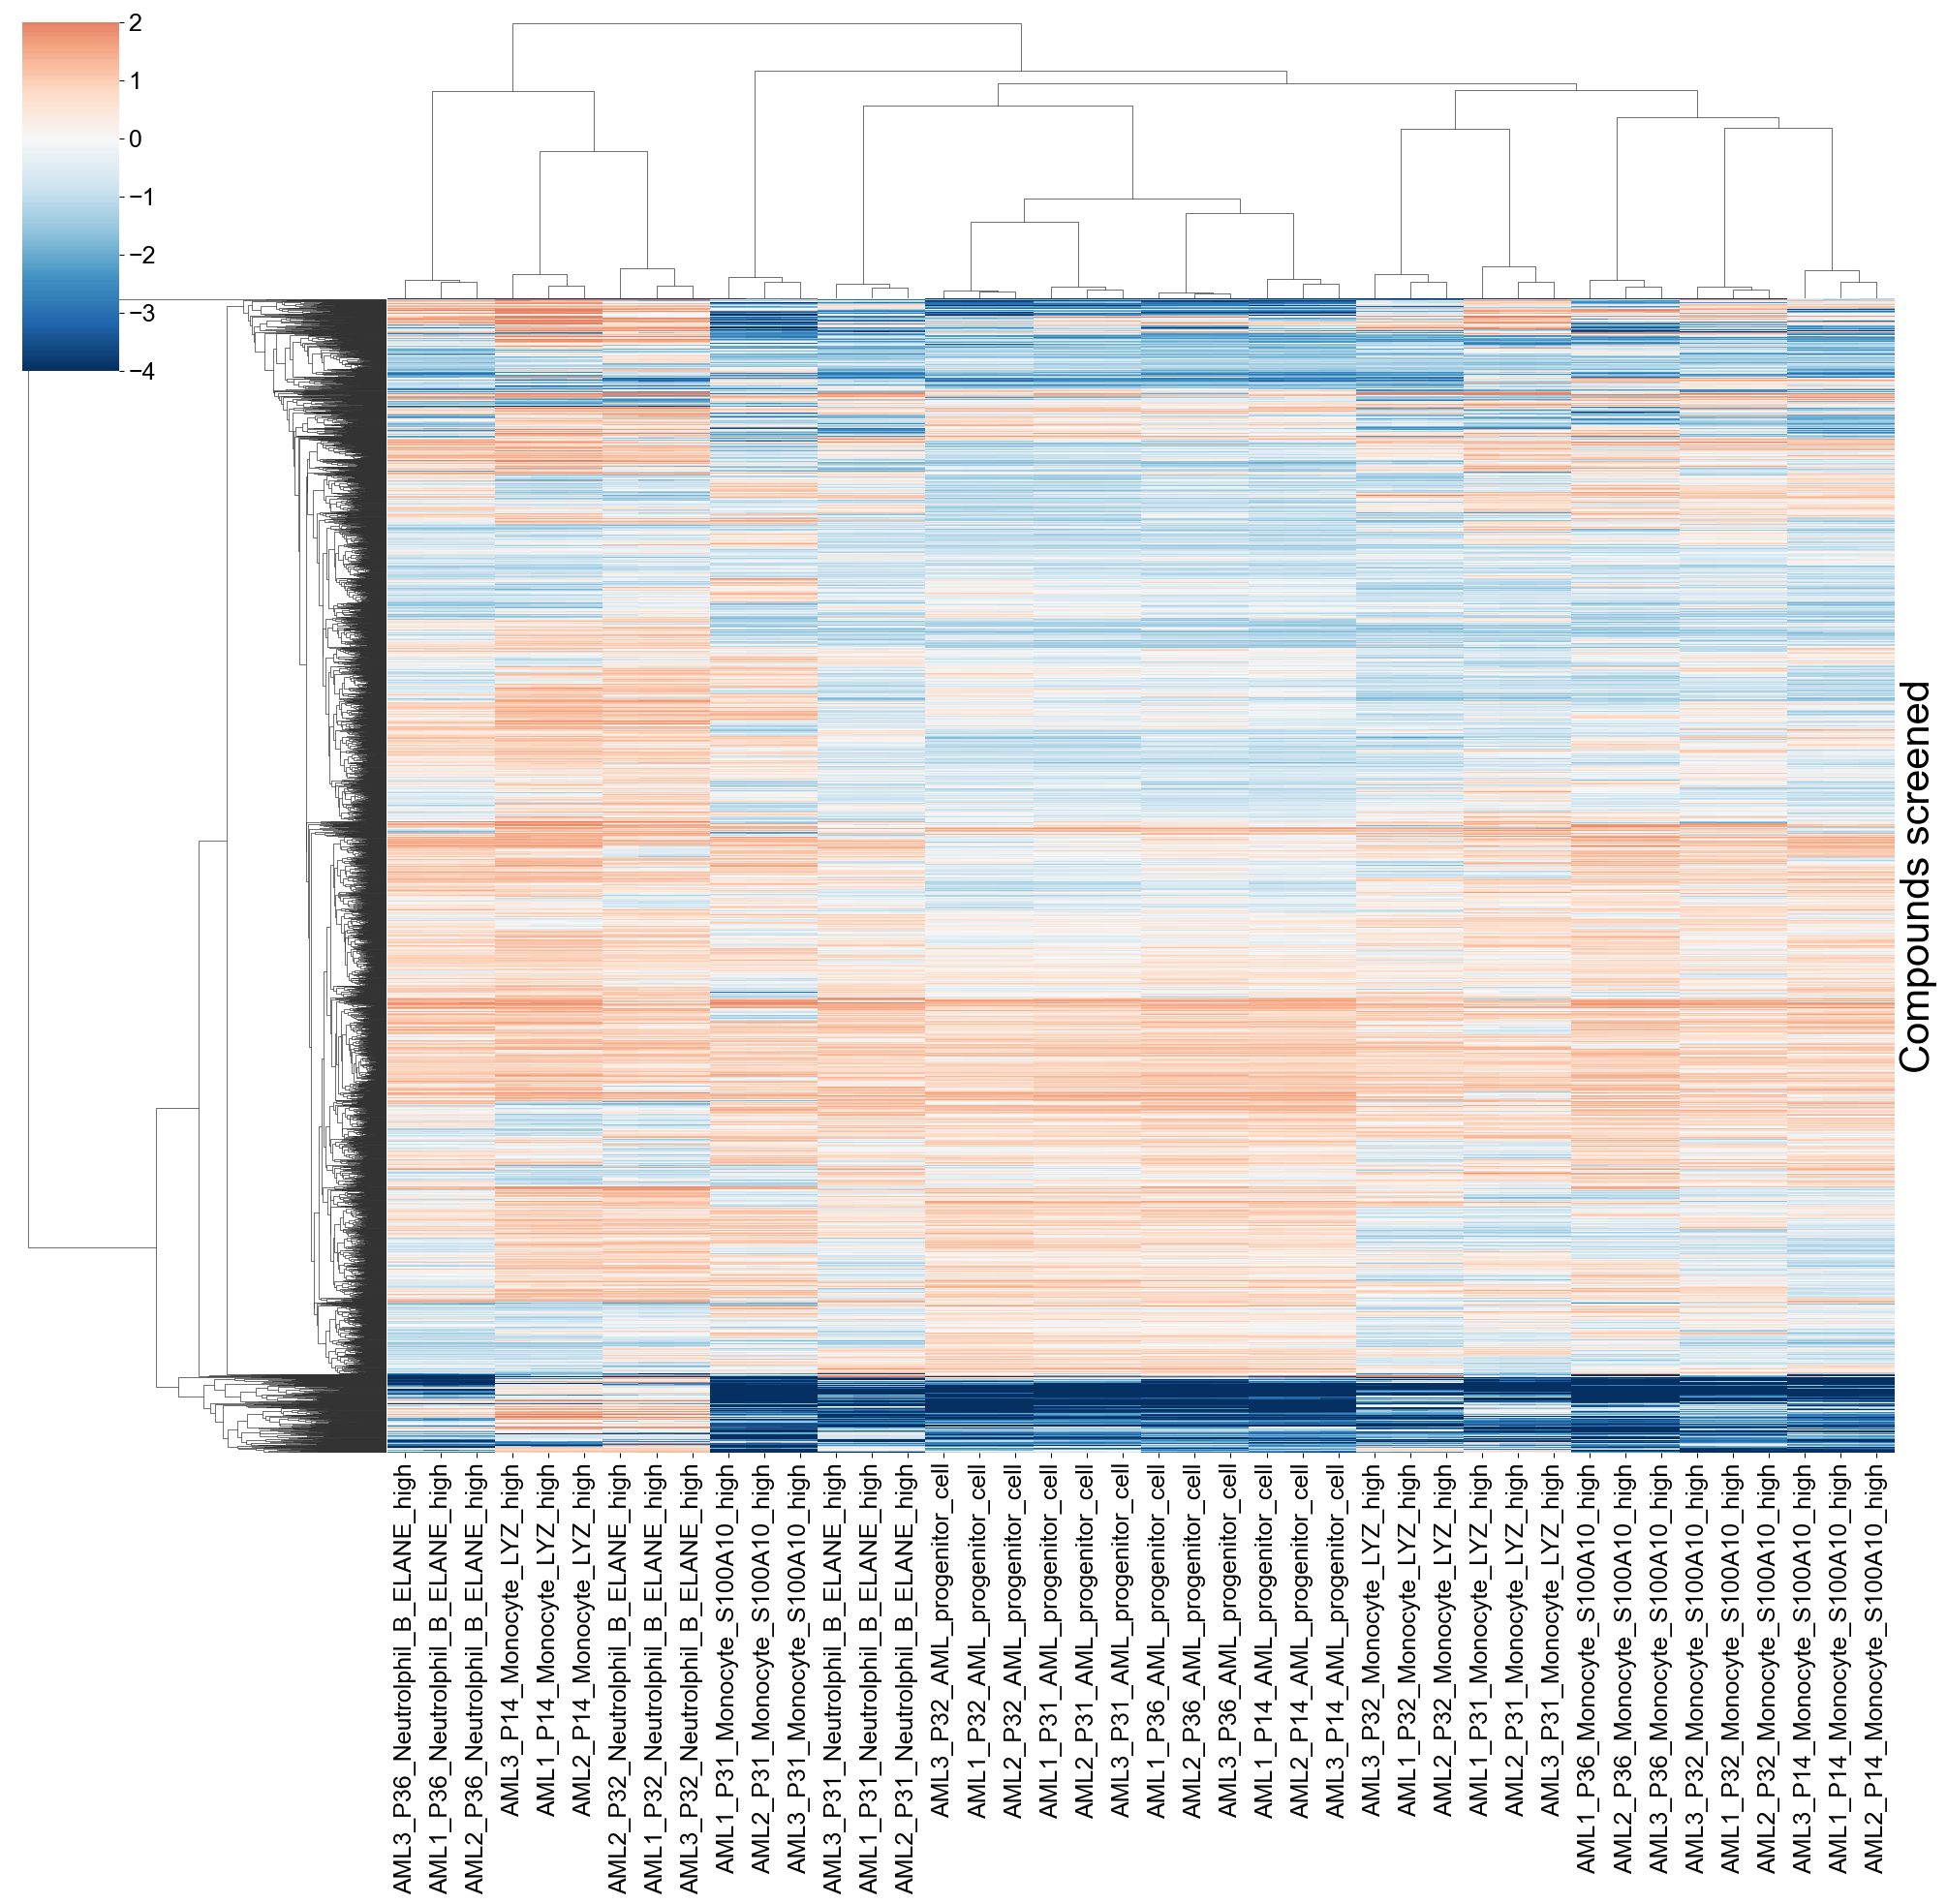

In [71]:
g = sns.clustermap(pbmc_df, figsize=(20, 20), cmap='RdBu_r', center=0, vmax=2, vmin=-4, yticklabels=False)
g.ax_heatmap.set_ylabel("Compounds screened", fontsize=30)
plt.show()

In [72]:
elane = pbmc_df[pbmc_df.columns[pbmc_df.columns.str.contains('Neutrolphil_B_ELANE_high')]]
elane = elane[elane < -2].fillna(0)
elane['Sum'] = elane.sum(axis=1)
elane_drugs = elane[elane.Sum != 0].sort_values('Sum').replace({0:np.nan}).dropna(thresh=2)

target_cells = pbmc_df[pbmc_df.columns[~pbmc_df.columns.str.contains('Neutrolphil_B_ELANE_high')]]
target_cells = target_cells[target_cells < -2].fillna(0)
target_cells['Sum'] = target_cells.sum(axis=1)
target_cells_drugs = target_cells[target_cells.Sum != 0].sort_values('Sum').replace({0:np.nan}).dropna(thresh=5).head(200)

final_drugs = list(set(target_cells_drugs.index) - set(elane_drugs.index))
final_df = pbmc_df.loc[final_drugs]
final_df['Sum'] = final_df.sum(axis=1)
final_df = final_df.sort_values('Sum')
final_df = final_df[final_df.Sum < -2]
final_df['Sum_ELANE'] = final_df[final_df.columns[final_df.columns.str.contains('Neutrolphil_B_ELANE_high')]].sum(axis=1)
final_df = final_df.sort_values('Sum_ELANE', ascending=False)
final_df = final_df[final_df.Sum_ELANE > 0]
final_df = final_df.drop('Sum', axis=1)
final_df = final_df.drop('Sum_ELANE', axis=1)

top_ind = list(set(final_df.index) & set(meta_data.index))
all_ind = list(set(pbmc_df.index) & set(meta_data.index))

top_meta = meta_data.loc[top_ind]
all_meta = meta_data.loc[all_ind]

top_vals = []
for i in top_meta.MOA.dropna().values:
    if len(i.split(',')) > 1:
        iii = i.split(', ')
        for ii in iii:
            top_vals.append(ii)
    else:
        top_vals.append(i)

all_vals = []
for i in all_meta.MOA.dropna().values:
    if len(i.split(',')) > 1:
        iii = i.split(', ')
        for ii in iii:
            all_vals.append(ii)
    else:
        all_vals.append(i)

uniq = list(set(top_vals))

list_drug = []
list_pval = []
list_count = []

for u in uniq:
    len_top = len(top_vals)
    len_all = len(all_vals)

    count = Counter(top_vals)[u]

    top_feat = len([k for k in top_vals if k == u])
    all_feat = len([k for k in all_vals if k == u])

    if top_feat > 0:
        pval = hypergeom.sf(k=top_feat, M=len_all, n=all_feat, N=len_top, loc=0)
    else:
        pval = 1
    list_drug.append(u)
    list_pval.append(pval)
    list_count.append(count)

padj = p_adjust_bh(list(list_pval)).tolist()

perm={
    "Category":list_drug,
    "N":list_count,
    "pval":list_pval,
    "padj":padj
}

enrich = pd.DataFrame(perm)
enrich = enrich[enrich['N'] > 1]
enrich = enrich[enrich.padj < 0.05]
class1 = list(set(meta_data[meta_data.MOA == 'HDAC inhibitor'].index) & set(top_ind))
class2 = list(set(meta_data[meta_data.MOA == 'acetylcholine receptor agonist'].index) & set(top_ind))
class3 = list(set(meta_data[meta_data.MOA == 'tubulin polymerization inhibitor'].index) & set(top_ind))
top1 = pbmc_df.loc[class1].sum(axis=1).sort_values().index[0]
top2 = pbmc_df.loc[class2].sum(axis=1).sort_values().index[0]
top3 = pbmc_df.loc[class3].sum(axis=1).sort_values().index[0]
select_top = DataFrame(pbmc_df.loc[[top1, top2, top3]])
select_top['Type'] = 'Top'
select_mid = pbmc_df[pbmc_df > -1]
select_mid = select_mid[select_mid < 0].dropna()
select_mid['Type'] = 'Mid'
select_bot = pbmc_df[pbmc_df > 0.75].dropna()
select_bot['Type'] = 'Bottom'
candidates = pd.concat([select_top, select_mid, select_bot])

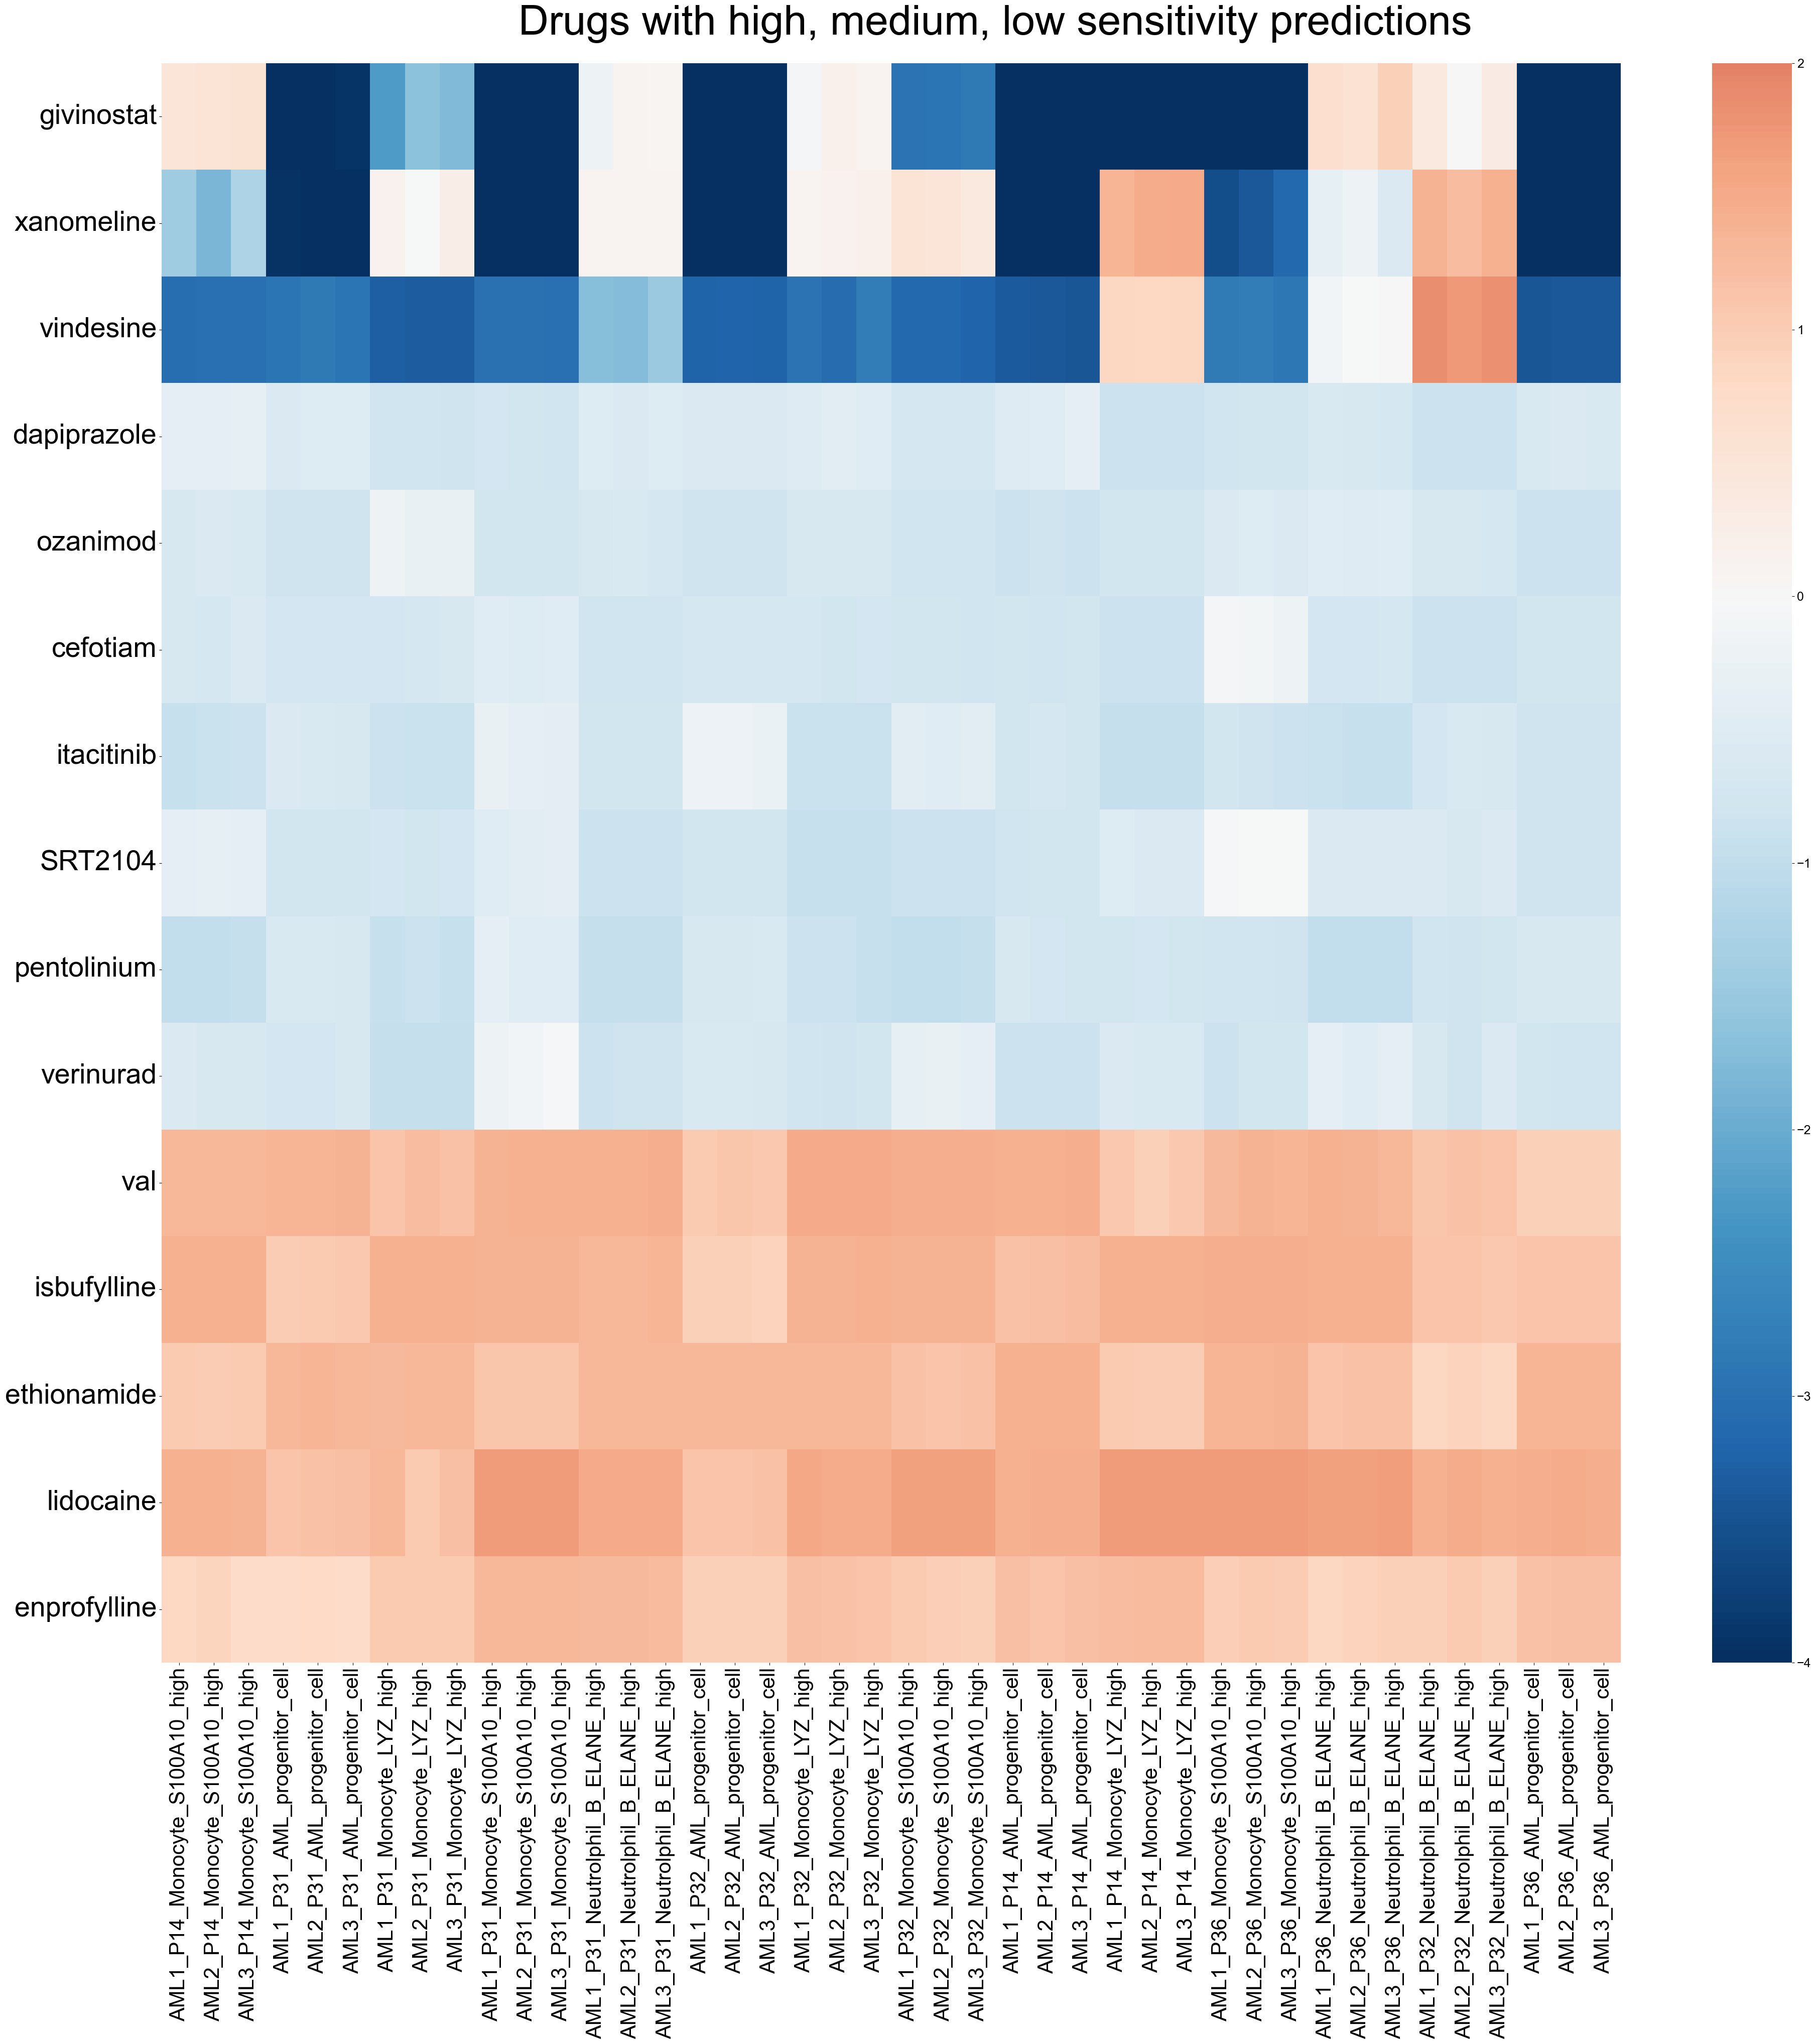

In [74]:
plt.figure(figsize=(40, 40))
ax = sns.heatmap(candidates.drop('Type', axis=1), vmax=2, center=0, vmin=-4, cmap='RdBu_r')

ax.tick_params(axis='x', labelsize=30)
ax.tick_params(axis='y', labelsize=40, rotation=0) 

plt.tight_layout()
plt.suptitle("Drugs with high, medium, low sensitivity predictions", fontsize=60, y=1.02)
plt.savefig(f"{FIGURE_DIR}/Fig_final_cand_sel.pdf", format="pdf", bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

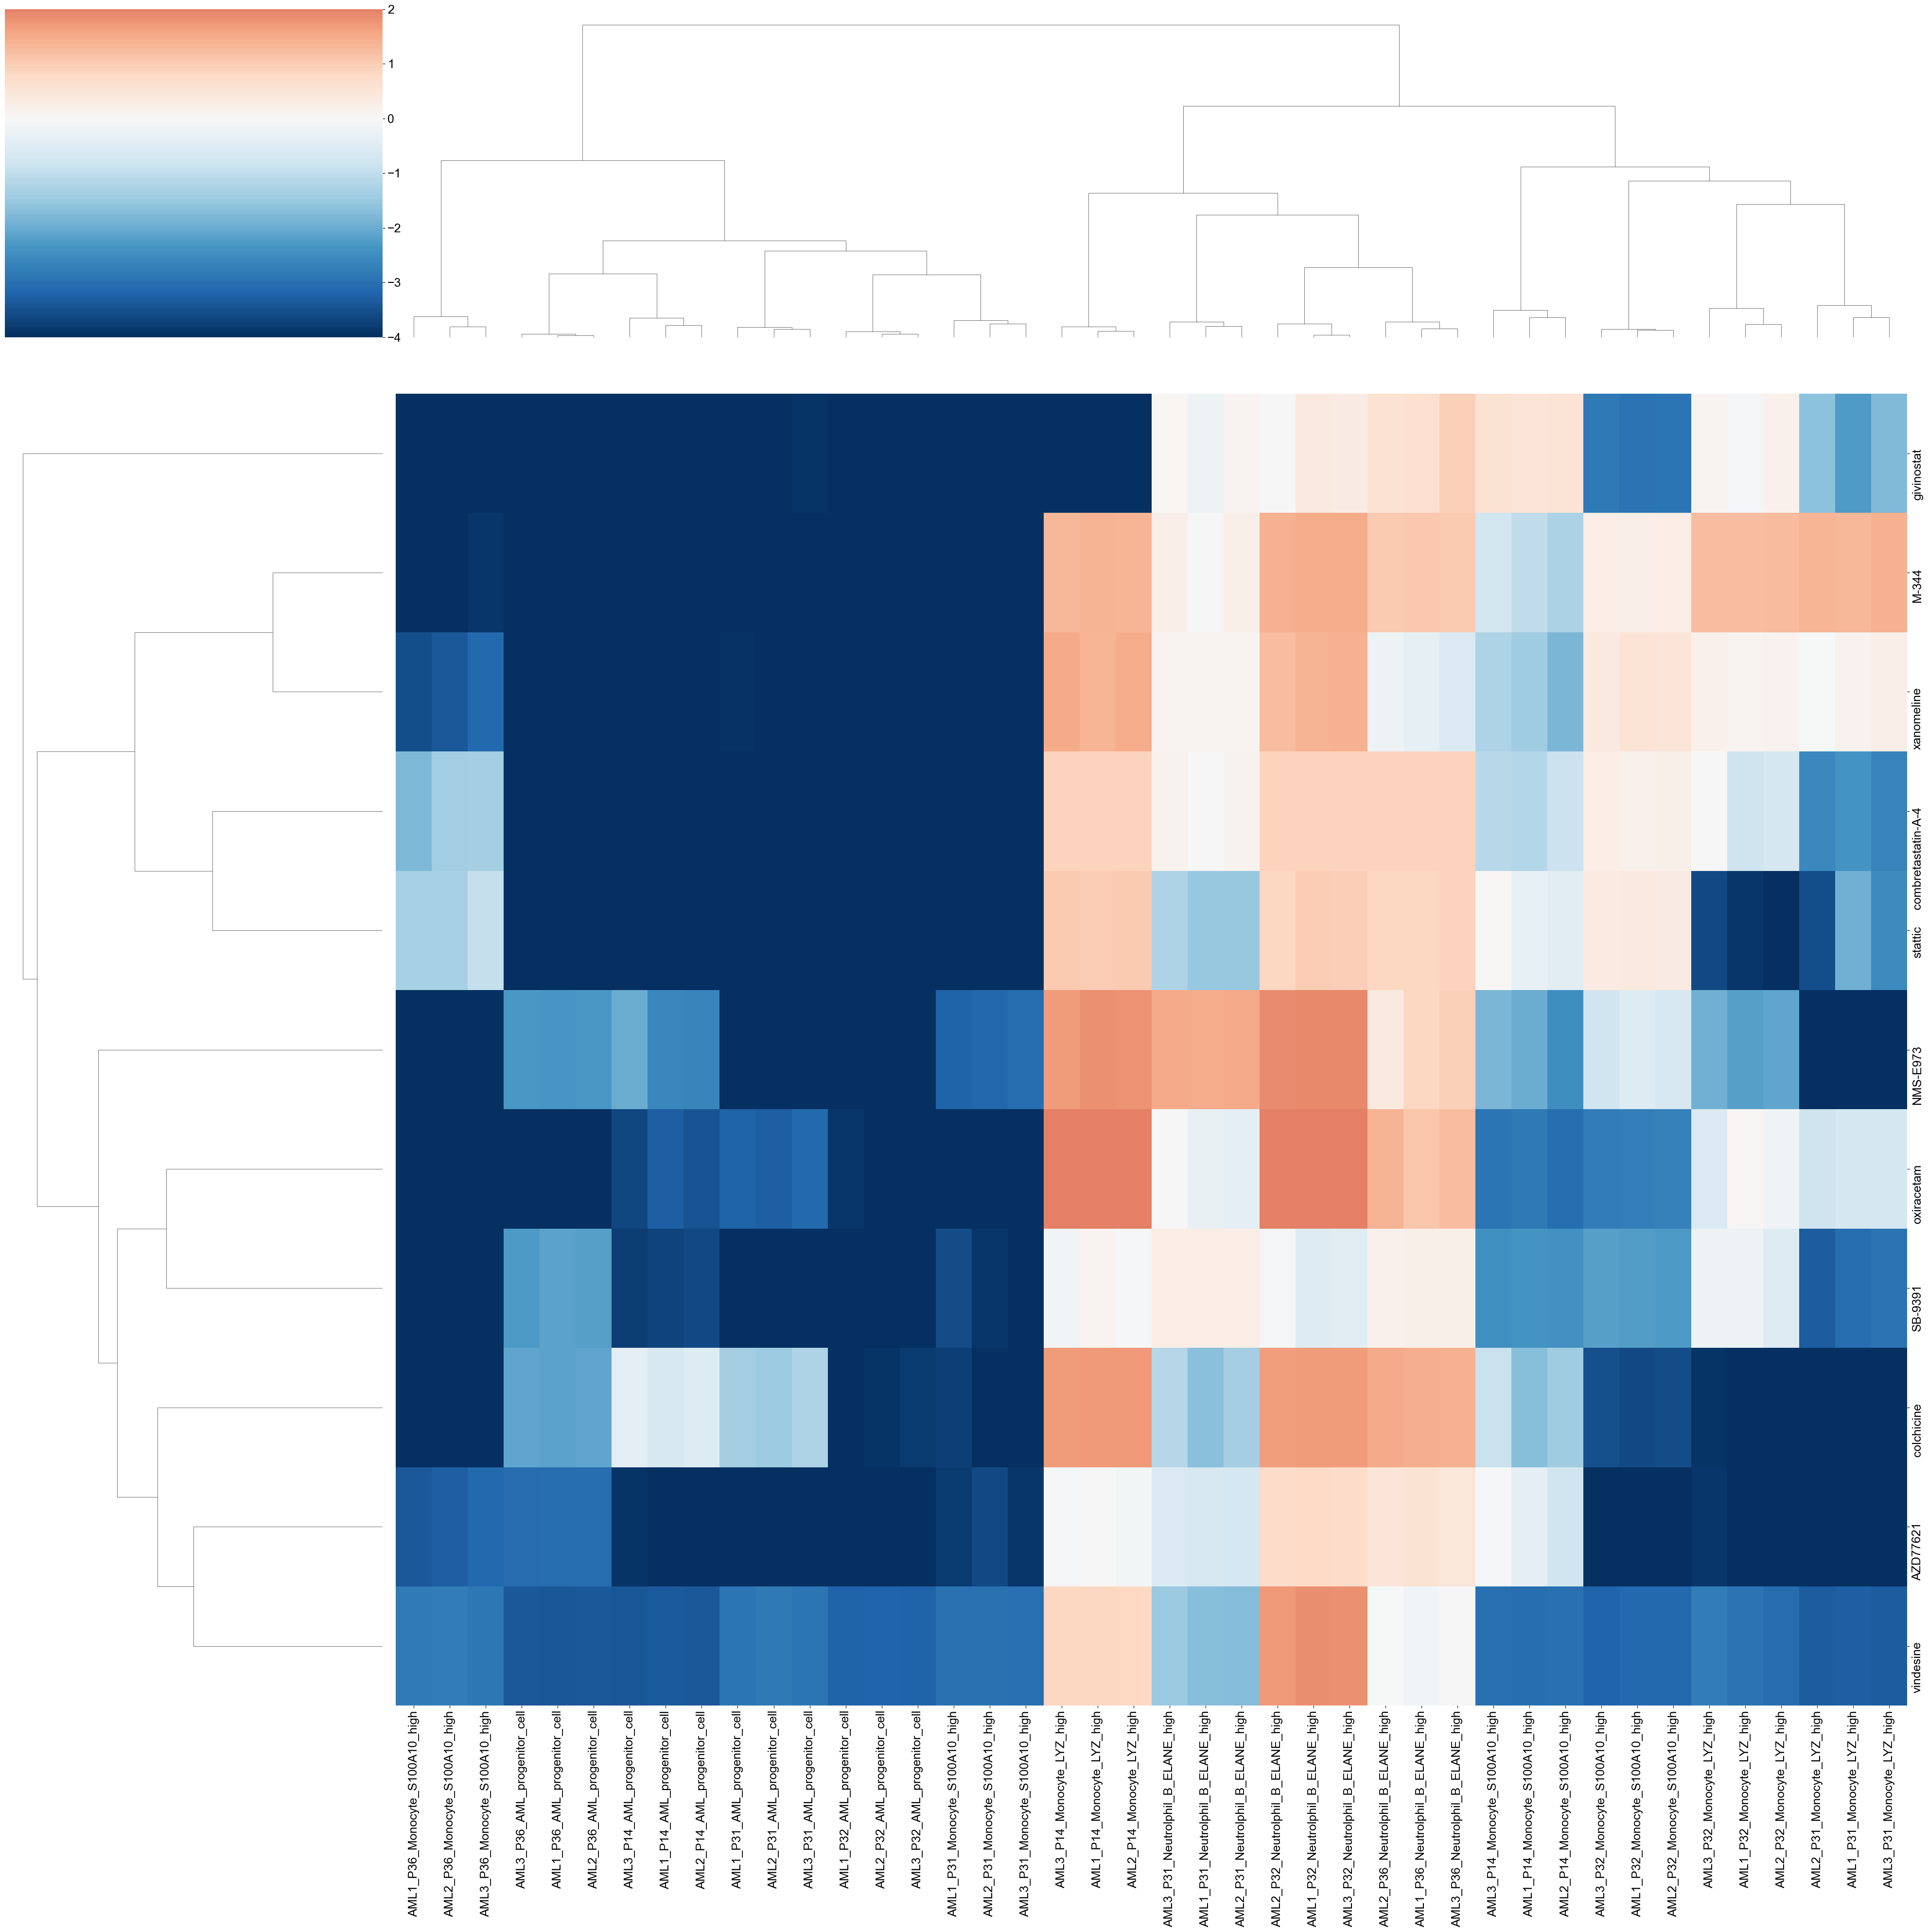

In [75]:
plt.figure()
sns.clustermap(final_df, figsize=(40,40), vmax=2, center=0, vmin=-4, cmap='RdBu_r')
plt.tight_layout()
plt.show()

In [76]:
exviv_rank = mix_df.copy()
exviv_rank['Sum'] = exviv_rank.sum(axis=1)
exviv_rank = exviv_rank.sort_values('Sum')
exviv_rank['Rank'] = exviv_rank.Sum.rank()
vald_exviv = exviv_rank.loc[list(set(exvivo_df.OCTAD_Drug.dropna()) & set(exviv_rank.index))]

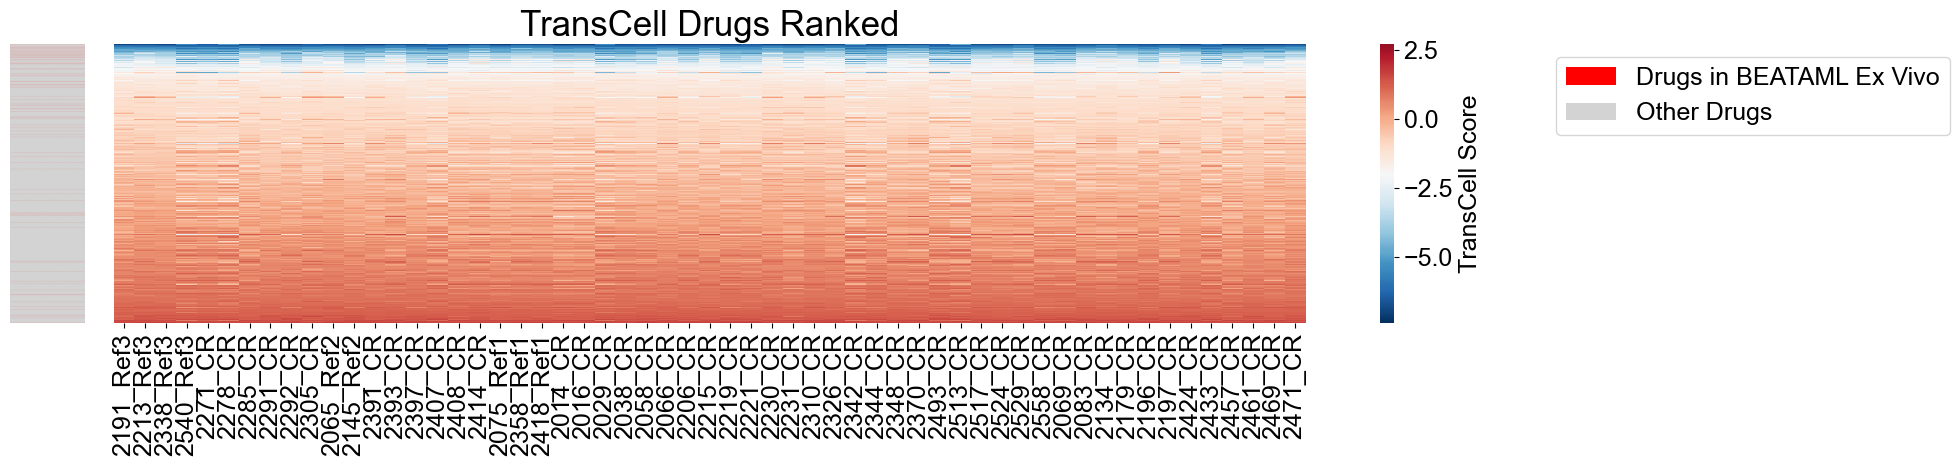

In [77]:
plot_df = exviv_rank.head(5000)

highlighted_rows = list(vald_exviv.index)

fig, (ax_colorbar, ax_heatmap) = plt.subplots(
    ncols=2, 
    gridspec_kw={'width_ratios': [0.05, 1]}, 
    figsize=(20, 5)
)

cmap = colors.ListedColormap(['lightgrey', 'red'])
color_labels = [1 if gene in highlighted_rows else 0 for gene in plot_df.index]
ax_colorbar.imshow(np.array(color_labels).reshape(-1,1), aspect='auto', cmap=cmap)
ax_colorbar.axis('off')

sns.heatmap(plot_df.drop('Rank', axis=1).drop('Sum', axis=1), cmap='RdBu_r', ax=ax_heatmap, cbar=True, yticklabels=False, cbar_kws={'label': 'TransCell Score'}, xticklabels=True, center=-2)
ax_heatmap.set_title('TransCell Drugs Ranked', fontsize=25)

# Add legend for colorbar
legend_elements = [
    Patch(facecolor='red', label='Drugs in BEATAML Ex Vivo'),
    Patch(facecolor='lightgrey', label='Other Drugs')
]
ax_heatmap.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.2, 1))

plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/Fig_Total_prediction.pdf", format="pdf", bbox_inches="tight")
plt.show()